<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/QML_SDNIntrusionDetection_Lazaro2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quantum machine learning for intrusion detection in software-defined networks: Lazaro et al. (2025) step by step

This notebook re-implements, runs and checks the experiment of

> Joan Lo Anguera, José Antonio Lázaro, Javier Ruiz-Hidalgo, Àlex Solé, Josep Ramon Casas, Samael Sarmiento and Adolfo Lerín,
> "Leveraging Quantum Machine Learning for Intrusion Detection in Software-Defined Networks",
> *2025 IEEE International Conference on Machine Learning for Communication and Networking (ICMLCN)*, 2025. DOI [10.1109/ICMLCN64995.2025.11140473](https://doi.org/10.1109/ICMLCN64995.2025.11140473)

The paper takes the **UNR-IDD** data set (University of Nevada, Reno; port statistics collected from an emulated SDN with ONOS and Open vSwitch), reduces it to **four features**
and compares four families of quantum models on quantum simulators with classical counterparts: **quantum k-nearest neighbours** (QKNN-V1 with angle and amplitude encoding, QKNN-V2, QKNN-V3),
a **quantum support vector machine** (QSVM, PennyLane), a **quantum neural network** (QNN, Qiskit `SamplerQNN`, COBYLA) and a **hybrid quantum neural network** (HQNN, Qiskit `TorchConnector` + a classical network).
Every model is run for the binary task (normal vs attack) and the multiclass task (normal + five attacks). Its headline claim: HQNN (78.24 %) and QSVM (72.40 %) beat the classical NN (77.10 %) and SVM (69.65 %) in the multiclass case (Tables I and II).

**What the notebook does.**
1. Downloads the real UNR-IDD file (public GitHub copies, sha-256 checked), repeats the paper's cleaning and feature-selection steps, and draws the real classes and a 2-D view of the real flows.
2. Trains the classical models of Table I (RF, KNN, SVM, NN) on the same four features.
3. Re-implements every quantum model of Table II. The swap-test circuits of the QKNN, the QSVM kernel circuit and the QNN/HQNN circuits are drawn, and each fast simulator that is used for the large loops is **asserted equal** to the Qiskit/PennyLane circuit that is drawn.
4. Prints the paper's numbers next to the notebook's with a verdict per claim, then reads the paper critically.

**How to run.** Colab, CPU runtime, *Runtime -> Run all*. No quantum hardware, no account, no Hugging Face token and no API key are needed (the data are open; UNR-IDD is not on the Hub). With `FAST_MODE = True`
(2,500 flows, 100 COBYLA evaluations, 6 HQNN epochs, one seed, 16 QKNN-V3 test flows) it takes about 10 minutes on a CPU; with `FAST_MODE = False` (the paper's budgets: 10,000 flows, COBYLA 600, 50 HQNN epochs, three seeds) see the runtime note in the configuration cell.
If you ever point the notebook at a gated Hugging Face data set, add your own token as a Colab Secret named `HF_TOKEN`; it is read from `os.environ["HF_TOKEN"]` or Colab Secrets and never printed.

**What you get at the end.** Test accuracy and macro-F1 of 18 models (mean +- std over seeds), the paper's Figures 10 and 11 and Tables I and II redrawn next to ours, a verdict for each checkable claim,
and a critical reading of what the experiment does and does not show.

## The paper in one page

**Problem.** Intrusion detection in software-defined networks (SDN): the controller can read per-port counters of every switch, so a classifier on these port statistics can flag attacks quickly. The authors ask whether quantum models can match or beat classical ones on this task.

**Decision.** Two tasks on every flow record: *binary* (normal vs attack) and *multiclass* (Normal, Blackhole, Diversion, Overflow = flow-table overflow, PortScan, TCP-SYN flood). Metrics: accuracy and "mean F1" (Table I only).

**Data.** UNR-IDD (Das et al., CCNC 2023): 37,411 rows, 34 columns (Mininet, 10 hosts, 12 Open vSwitches, ONOS controller, iPerf traffic), about 90 % attack / 10 % normal.

**Preprocessing (Section II).** One duplicate row removed; 13 columns removed (identifiers and columns that are constant); a random-forest importance ranking of the remaining 19 columns; all 4-element combinations of the 10 most important features scored with RF, KNN, SVM and NN
(80/20 split); best multiclass combination = **Port alive Duration (S), Packets Matched, Packets Looked Up, Active Flow Entries**. Four features because four qubits give a 16-dimensional state. Sample size chosen by a sweep from 500 to 30,000 flows: **10,000 flows** (200 for QKNN-V3), 80 % train / 20 % test.

**Models (Section III).**
* **QKNN-V1**: swap-test circuit (ancilla + controlled-SWAP) whose ancilla statistics give a distance, 2048 shots; *amplitude* encoding (`D = 4Z(P(0) - 1/2)`, i.e. the squared Euclidean distance) or *angle* encoding (`U(theta, gamma)` on features 1 and 2 only, angles `7*pi/2*(a + 1)`, `D = sqrt(Z P(1))`).
* **QKNN-V2**: angle encoding of all four features on two qubits per state, angles `pi/2*(a + 1)`, two controlled-SWAPs, `D = sqrt(Z P(1))`, 2048 shots (Fig. 1).
* **QKNN-V3**: the algorithm of Basheer et al. with a state-loading oracle `W|0>|i> = |phi_i>|i>`, swap test and Grover's search; only 200 samples because of the simulation cost.
* **QSVM**: PennyLane, kernel `|<0|U^dagger(x_j) U(x_i)|0>|^2` with a "slightly modified" ZZFeatureMap (Fig. 2), analytic execution, classical SVM on the precomputed Gram matrix.
* **QNN**: Qiskit `SamplerQNN`; (ZZFeatureMap + EfficientSU2) or (PauliFeatureMap + RealAmplitudes), four ansatz repetitions, quantum pooling (Fig. 4) down to 1 qubit (binary) or 3 qubits (multiclass), COBYLA with 600 iterations, L2 loss (binary) / cross-entropy (multiclass), parameter-shift gradients.
* **HQNN**: the same quantum layers through `TorchConnector` into a classical network with two hidden layers, dropout, batch normalisation and Leaky ReLU; 50 epochs of Adam (parameter-shift for the quantum layer); binary cross-entropy / cross-entropy.

**Claims to check (Tables I and II).** Accuracy in %, binary / multiclass:

| Model | Binary | Multiclass | | Classical | Binary | Multiclass |
|---|---|---|---|---|---|---|
| QKNN-V1 (angle) | 100 | 46.80 | | RF | 100 | 87.35 |
| QKNN-V1 (amplitude) | 90.05 | 19.80 | | KNN | 100 | 81.45 |
| QKNN-V2 | 100 | 56.90 | | SVM | 100 | 69.65 |
| QKNN-V3 (200 flows) | 85 | 55 | | NN | 99.50 | 77.10 |
| QSVM | 100 | 72.40 | | | | |
| QNN | 98.90 | 63.55 | | | | |
| HQNN | 100 | 78.24 | | | | |

Table I also lists a "mean F1" (RF 100 / 87.71, KNN 100 / 89.35, SVM 100 / 67.73, NN 98.64 / 73.25). The conclusion: HQNN (78.24) beats the NN (77.10) and QSVM (72.40) beats the SVM (69.65).

## What follows the paper and what had to be chosen

Choices are marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Data | UNR-IDD, 37,412 samples x 34 features ("Kaggle / UNR" release) | the original `UNR-IDD.csv` (37,411 rows, 34 columns) from public GitHub copies, byte-identical, sha-256 recorded in the code; one duplicate row dropped (37,410 rows) |
| Feature selection | RF importance of the 19 remaining columns, all 4-combinations of the top 10, scored with RF / KNN / SVM / NN on the test split | the same 13 columns removed (13 + 19 = 32 inputs), RF importance, all 4-combinations of the top 10 (top 7 in `FAST_MODE`) **scored with a random forest on a validation part of the training split**; the paper's four features are then used in the order the paper lists them |
| Sample, split | 10,000 flows, 80 / 20, "dataset shuffled between runs"; 200 flows for QKNN-V3 | random 10,000 flows (natural class proportions, seeded), stratified 80 / 20; 200 flows for QKNN-V3; one draw per seed, mean +- std over seeds |
| Scaling | not stated | QKNN encodings: features min-max scaled to [-1, 1] (so that `a + 1` of the paper is in [0, 2]); QSVM / QNN / HQNN / classical models: min-max scaled to [0, pi]; fitted on the training split only, test values clipped |
| Classical models | RF, KNN, SVM, NN (no hyper-parameters given) | `RandomForestClassifier(100)`, `KNeighborsClassifier()` (k = 5), `SVC(rbf, C=1)`, `MLPClassifier((64, 32))`, on the same [0, pi] inputs as the quantum models |
| k of the quantum KNNs | not given | k = 5 (sklearn default, which the paper's `KNeighborsClassifier()` uses) |
| QKNN-V1 / V2 | circuits of Diadamo et al., 2048 realisations | the circuits are built in Qiskit and asserted equal to closed forms; the large test x train distance matrices (up to 2000 x 8000) are filled with the closed forms and **binomial shot noise for 2048 shots**; ties broken at random |
| QKNN-V1 angle factor | `7*pi/2`, "may vary" | `7*pi/2` as written; ablation with `pi/2` |
| QKNN-V3 | Basheer et al. with an oracle and Grover's algorithm, details not given | reconstruction: uniform superposition over the 160 training indices, oracle `W` that loads the state phi_i of training flow i into the train register, controlled on the index register (a 1024 x 1024 block-diagonal unitary), swap test against the test state (V2 angle encoding), Grover iterations on the ancilla-0 branch (**number of iterations: 0, because the marked probability is always above 1/2 and the first iteration would overshoot**), 2048 shots on the index register, the 5 most frequent indices vote. Extra row: an idealised threshold oracle. |
| QSVM feature map | "slightly modified ZZFeatureMap with X and RZ gates" (Fig. 2, not machine-readable) | the standard ZZFeatureMap (2 reps, full entanglement) written with H, RZ and CNOT in PennyLane, asserted equal to Qiskit's; the "modification" is unknown. Analytic kernel, `SVC(C=1)`; extra row: angle scale (kernel bandwidth) tuned on a validation split |
| QNN circuit | feature map + ansatz (4 repetitions) + pooling (Fig. 4), 4 qubits | feature map with the library default of 2 repetitions, ansatz with 4; the pooling circuit of the Qiskit QCNN tutorial (3 parameters per pair); binary: pool 4 -> 1 qubit, multiclass: pool 4 -> 3 qubits |
| PauliFeatureMap | not given | library default Paulis `['Z', 'ZZ']`, which **is the same circuit as the ZZFeatureMap**; the two combinations then differ only in the ansatz |
| Multiclass read-out | 3 qubits for 6 classes | the 8 outcomes of 3 qubits; classes 0-5 are targets, outcomes 6 and 7 are never targets |
| QNN training | `SamplerQNN`, COBYLA 600 iterations, parameter-shift | COBYLA with 600 function evaluations on the full training set, initial weights uniform [0, 1); an exact PyTorch state-vector engine replaces the sampler (asserted equal to Qiskit in the circuit-architecture section below) |
| HQNN | `TorchConnector`, two hidden layers, dropout, batch norm, Leaky ReLU, 50 epochs Adam, parameter-shift | hidden widths (32, 16), dropout 0.2, batch 256 (128 in `FAST_MODE`), learning rate 0.01, initial circuit weights uniform [-1, 1); autograd through the exact engine (asserted equal to the parameter-shift rule, to 1e-9) |
| Shots (QSVM, QNN, HQNN) | not given, analytic for the QSVM | exact probabilities |
| Validation set | none ("models generalised well") | none for the models of the paper; the extra QSVM bandwidth row uses a validation split of the training data |
| Runs | one | one run per seed, mean +- std (`SEEDS`) |

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib, torch, sympy and scipy.
# The pip line runs on Colab (or wherever Qiskit / PennyLane are missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
_missing = [m for m in ("qiskit", "qiskit_machine_learning", "qiskit_aer", "pennylane", "pylatexenc") if importlib.util.find_spec(m) is None]
if IN_COLAB or _missing:
    %pip -q install "qiskit==2.5.2" "qiskit-machine-learning==0.9.1" "qiskit-aer==0.17.2" "pennylane==0.45.1" pylatexenc requests
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("qiskit, qiskit-machine-learning, qiskit-aer, pennylane already present; skipping pip install.")

qiskit, qiskit-machine-learning, qiskit-aer, pennylane already present; skipping pip install.


In [2]:
# ---------------- configuration: every tunable constant is here ----------------
FAST_MODE = False             # True: class demo in about 10 minutes (small samples, few iterations, one seed).
                              # False: the paper's budgets (10,000 samples, COBYLA 600, 50 HQNN epochs, 3 seeds): about 65 minutes on a quiet 8-core CPU, 100 minutes measured while other jobs shared it.
SEED = 42                     # master seed (CHOICE: the paper gives none)

# ---- data (UNR-IDD) ----
FEATURES = ["Port alive Duration (S)", "Packets Matched", "Packets Looked Up", "Active Flow Entries"]   # the paper's 4 selected features, in the order the paper lists them
TEST_SIZE = 0.20              # paper: 80 % train / 20 % test
N_V3 = 200                    # paper: QKNN-V3 uses only 200 samples

if FAST_MODE:
    N_SAMPLES   = 2500        # paper: 10,000 samples for every model except QKNN-V3
    SEEDS       = [42]        # every model is run once per seed (different 10,000-sample draw and split)
    SEEDS_V3    = [42]
    N_V3_TEST   = 16          # QKNN-V3 test points simulated (paper: 40 = 20 % of 200)
    COBYLA_ITERS = 100        # paper: 600
    HQNN_EPOCHS  = 8          # paper: 50
    SEEDS_HQNN   = [42]       # HQNN trains a circuit through autograd (about 0.2 s per step on a shared CPU): fewer seeds than the other models
    HQNN_BATCH   = 128        # CHOICE: not given
    TOP_FOR_COMBOS = 7        # feature-combination search over the top-N important features (paper: 10 -> 210 combinations of 4)
    RF_TREES_SEARCH = 25
else:
    N_SAMPLES   = 10000
    SEEDS       = [42, 43, 44]
    SEEDS_V3    = [42, 43, 44, 45, 46]
    N_V3_TEST   = 40
    COBYLA_ITERS = 600
    HQNN_EPOCHS  = 50
    SEEDS_HQNN   = [42, 43, 44]   # HQNN: 5 runs of 50 epochs per seed take about 12 minutes on a shared CPU
    HQNN_BATCH   = 256        # CHOICE: not given (kept large to bound the runtime)
    TOP_FOR_COMBOS = 10
    RF_TREES_SEARCH = 40

# ---- quantum models ----
SHOTS_KNN   = 2048            # paper: QKNN-V1 / V2 circuits "run for 2048 realizations"
SHOTS_V3    = 2048            # CHOICE: shots of the QKNN-V3 index measurement (paper: not given)
K_NEIGHBOURS = 5              # CHOICE: sklearn default KNeighborsClassifier(), the paper does not give k
FM_REPS     = 2               # CHOICE: feature-map repetitions (library default); the ansatz uses 4 repetitions as in the paper's Figures 5-6
ANSATZ_REPS = 4
V1_ANGLE_FACTOR = 7 * 3.141592653589793 / 2   # paper, QKNN-V1: a' = (7*pi/2)(a + 1), "may vary with the data set"
V2_ANGLE_FACTOR = 3.141592653589793 / 2       # paper, QKNN-V2: a' = (pi/2)(a + 1)
V3_GROVER_ITERATIONS = None   # CHOICE: the paper says Grover's search is included, not how many iterations. None: k = 0 when the marked probability is above 1/2 (always the case here), else the usual formula; an integer forces it
HQNN_LR     = 0.01            # CHOICE: Adam learning rate, not given
HQNN_HIDDEN = (32, 16)        # CHOICE: "two hidden layers", widths not given
HQNN_DROPOUT = 0.2            # CHOICE
QSVM_C      = 1.0             # CHOICE: sklearn default, the paper gives no C

DATA_DIR = "lazaro2025_data"  # cache folder
UNR_PATH = None               # or the path of an uploaded UNR-IDD.csv
IBM_TOKEN = ""                # unused: the paper uses simulators only
print(f"FAST_MODE={FAST_MODE}  N_SAMPLES={N_SAMPLES}  SEEDS={SEEDS}  COBYLA_ITERS={COBYLA_ITERS}  HQNN_EPOCHS={HQNN_EPOCHS}  N_V3_TEST={N_V3_TEST}")

FAST_MODE=False  N_SAMPLES=10000  SEEDS=[42, 43, 44]  COBYLA_ITERS=600  HQNN_EPOCHS=50  N_V3_TEST=40


In [3]:
import os, time, math, hashlib, warnings, json, itertools
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import requests, scipy, sklearn, sympy
import torch, torch.nn as nn, torch.nn.functional as F
import qiskit, qiskit_machine_learning
import pennylane as qml
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import (zz_feature_map, pauli_feature_map, efficient_su2, real_amplitudes,
                                    StatePreparation, UnitaryGate)
from qiskit.quantum_info import Statevector
from scipy.optimize import minimize
from scipy.linalg import block_diag
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score, precision_recall_fscore_support, confusion_matrix, ConfusionMatrixDisplay
warnings.filterwarnings("ignore")
from IPython.display import display

def show_fig(fig):
    """Qiskit's mpl drawer closes its figure in a notebook; display it explicitly."""
    display(fig); plt.close(fig)

def set_all_seeds(seed):
    np.random.seed(seed); torch.manual_seed(seed)
    from qiskit_machine_learning.utils import algorithm_globals
    algorithm_globals.random_seed = seed

set_all_seeds(SEED)
rng = np.random.default_rng(SEED)
torch.set_num_threads(2)
os.makedirs(DATA_DIR, exist_ok=True)
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| torch", torch.__version__,
      "| qiskit", qiskit.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__, "| pennylane", qml.__version__)

numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | torch 2.14.1+cpu | qiskit 2.5.2 | qiskit-machine-learning 0.9.1 | pennylane 0.45.1


## 1. Data: UNR-IDD

The University of Nevada, Reno intrusion detection dataset (UNR-IDD, Das et al., CCNC 2023) contains **port statistics** collected from an emulated SDN: 10 hosts, 12 Open vSwitches, a custom ONOS controller that sends
`OFPPortStatsRequest` messages, iPerf traffic of 10 Mbps between random host pairs every 5 s. Each row is the state of one switch port at one time; the label is `Normal` or one of five attacks
(TCP-SYN flood, Blackhole, Port scan, Flow-table overflow, Diversion). The notebook downloads the original CSV from public GitHub copies (the first three are byte-identical; the sha-256 of that file is recorded in the code and checked) and caches it in `DATA_DIR`.
If the downloads fail, upload `UNR-IDD.csv` (Kaggle: *UNR-IDD*, or the UNR project page) and set `UNR_PATH`. The data are open, so no token is needed.

In [4]:
UNR_URLS = [   # GitHub copies of the original UNR-IDD.csv (University of Nevada, Reno); the first three are byte-identical
    "https://raw.githubusercontent.com/Mazeker/Intrusion_Detection/main/UNR-IDD.csv",
    "https://raw.githubusercontent.com/Sindhujajishnu/UNR-IDD/main/UNR-IDD.csv",
    "https://raw.githubusercontent.com/anandhumohan/UNR-IDD-Classification/master/UNR-IDD.csv",
    "https://raw.githubusercontent.com/Shekswess/Federated-Network-Intrusion-Detection/main/src/dataset/initial_dataset/UNR-IDD.csv",
]
UNR_SHA256 = "70b33a29f952427975488961d7e8618befb9eb4f49b30483aeb82744930a612b"   # sha-256 of that file, recorded when this notebook was written

def load_unr():
    path = UNR_PATH or os.path.join(DATA_DIR, "UNR-IDD.csv")
    if not os.path.exists(path):
        err = None
        for url in UNR_URLS:
            try:
                r = requests.get(url, headers={"User-Agent": "Mozilla/5.0"}, timeout=120); r.raise_for_status()
                with open(path, "wb") as fh: fh.write(r.content)
                print("downloaded from", url); break
            except Exception as e:
                err = e; print("failed:", url, "->", e)
        else:
            raise RuntimeError(f"UNR-IDD could not be downloaded ({err}); upload UNR-IDD.csv and set UNR_PATH.")
    digest = hashlib.sha256(open(path, "rb").read()).hexdigest()
    print("UNR-IDD.csv sha-256 matches the recorded copy:", digest == UNR_SHA256)
    df = pd.read_csv(path)
    df.columns = [c.strip() for c in df.columns]
    for c in ("Label", "Binary Label"): df[c] = df[c].astype(str)
    return df

UNR_RAW = load_unr()
print("UNR-IDD as downloaded:", UNR_RAW.shape)

UNR-IDD.csv sha-256 matches the recorded copy: True


UNR-IDD as downloaded: (37411, 34)


## 2. Cleaning and feature selection (paper, Section II-A)

The paper removes the single duplicate, drops 13 columns (`Switch ID`, `Port Number`, the dropped / error counters and their deltas, `is_valid`, `Table ID`, `Max Size`), ranks the remaining 19 columns with a random forest, scores all 4-element combinations of
the 10 most important ones with RF, KNN, SVM and NN, and keeps the best multiclass combination: **Port alive Duration (S), Packets Matched, Packets Looked Up, Active Flow Entries**.

Here the first two steps are repeated exactly. The combination search is repeated with a random forest scored on a **validation part of the training split** (nothing is chosen on test data; the paper scores on its test split). Our importance ranking and therefore our top-10 can differ from the paper's, so the paper's own combination is scored too and
the notebook then uses the paper's four features in the order the paper lists them (feature 1 = `Port alive Duration (S)`, 2 = `Packets Matched`, 3 = `Packets Looked Up`, 4 = `Active Flow Entries`). The order matters for QKNN-V1 (angle), which only uses features 1 and 2.

In [5]:
PAPER_DROP = ["Switch ID", "Port Number", "Packets Rx Dropped", "Packets Tx Dropped", "Packets Rx Errors", "Packets Tx Errors",
              "Delta Packets Rx Dropped", "Delta Packets Tx Dropped", "Delta Packets Rx Errors", "Delta Packets Tx Errors",
              "is_valid", "Table ID", "Max Size"]                    # the 13 columns the paper removes (Section II-A)
LABEL_COLS = ["Label", "Binary Label"]

n_dup = int(UNR_RAW.duplicated().sum())
DF_ALL = UNR_RAW.drop_duplicates().reset_index(drop=True)            # the paper: "only a single duplicate that can be easily resolved"
print(f"duplicate rows: {n_dup}  -> {len(DF_ALL)} rows kept; missing values: {int(DF_ALL.isna().sum().sum())}")

zero_std = [c for c in DF_ALL.columns if c not in LABEL_COLS and DF_ALL[c].nunique() == 1]
print("constant columns (zero standard deviation):", zero_std)
print("non-numeric identifier columns:", [c for c in DF_ALL.columns if c not in LABEL_COLS and not pd.api.types.is_numeric_dtype(DF_ALL[c])])
print("paper's 13 removed columns that are NOT constant here (identifiers):", [c for c in PAPER_DROP if c not in zero_std])
CANDIDATES = [c for c in DF_ALL.columns if c not in LABEL_COLS + PAPER_DROP]
print(f"{len(CANDIDATES)} candidate features remain (paper: 19):")
print(CANDIDATES)

# --- importance ranking of the 19 features with a random forest (multiclass target), fitted on a training sample only
sel_rng_seed = SEED
d_sel = DF_ALL.sample(n=min(N_SAMPLES, len(DF_ALL)), random_state=sel_rng_seed)
tr_i, te_i = train_test_split(np.arange(len(d_sel)), test_size=TEST_SIZE, stratify=d_sel["Label"].to_numpy(), random_state=SEED)
Xs = d_sel[CANDIDATES].to_numpy(float); ys = d_sel["Label"].to_numpy()
rf_imp = RandomForestClassifier(200, random_state=SEED, n_jobs=1).fit(Xs[tr_i], ys[tr_i])
IMP = pd.Series(rf_imp.feature_importances_, index=CANDIDATES).sort_values(ascending=False)
print("\nRandom-forest importance (training split of the sample):"); print(IMP.round(4).to_string())
print("\nthe paper's four features and their importance rank:", {f: int(list(IMP.index).index(f)) + 1 for f in FEATURES})

duplicate rows: 1  -> 37410 rows kept; missing values: 0
constant columns (zero standard deviation): ['Packets Rx Dropped', 'Packets Tx Dropped', 'Packets Rx Errors', 'Packets Tx Errors', 'Delta Packets Rx Dropped', 'Delta Packets Tx Dropped', 'Delta Packets Rx Errors', 'Delta Packets Tx Errors', 'is_valid', 'Table ID', 'Max Size']
non-numeric identifier columns: ['Switch ID', 'Port Number']
paper's 13 removed columns that are NOT constant here (identifiers): ['Switch ID', 'Port Number']
19 candidate features remain (paper: 19):
['Received Packets', 'Received Bytes', 'Sent Bytes', 'Sent Packets', 'Port alive Duration (S)', 'Delta Received Packets', 'Delta Received Bytes', 'Delta Sent Bytes', 'Delta Sent Packets', 'Delta Port alive Duration (S)', 'Connection Point', 'Total Load/Rate', 'Total Load/Latest', 'Unknown Load/Rate', 'Unknown Load/Latest', 'Latest bytes counter', 'Active Flow Entries', 'Packets Looked Up', 'Packets Matched']



Random-forest importance (training split of the sample):
Port alive Duration (S)          0.2266
Packets Looked Up                0.1447
Packets Matched                  0.1430
Sent Packets                     0.0863
Sent Bytes                       0.0659
Received Bytes                   0.0615
Received Packets                 0.0600
Connection Point                 0.0533
Active Flow Entries              0.0306
Delta Received Bytes             0.0206
Unknown Load/Latest              0.0191
Delta Received Packets           0.0186
Delta Sent Bytes                 0.0183
Total Load/Latest                0.0146
Delta Sent Packets               0.0135
Latest bytes counter             0.0078
Total Load/Rate                  0.0065
Unknown Load/Rate                0.0058
Delta Port alive Duration (S)    0.0034

the paper's four features and their importance rank: {'Port alive Duration (S)': 1, 'Packets Matched': 3, 'Packets Looked Up': 2, 'Active Flow Entries': 9}


In [6]:
# Feature-combination search (paper, Section II-A): all 4-element combinations of the most important features, scored on the MULTICLASS task.
# CHOICE: the paper scores RF, KNN, SVM and NN on the test split; here a random forest is scored on a validation part of the TRAINING split
#         (so nothing is selected on test data), and the paper's own four features are then used regardless of the outcome.
top = list(IMP.index[:TOP_FOR_COMBOS])
tr_a, va_a = train_test_split(tr_i, test_size=0.25, stratify=ys[tr_i], random_state=SEED)
t0 = time.perf_counter(); combo_rows = []
for combo in itertools.combinations(top, 4):
    idx = [CANDIDATES.index(c) for c in combo]
    rf_ = RandomForestClassifier(RF_TREES_SEARCH, random_state=SEED, n_jobs=1).fit(Xs[tr_a][:, idx], ys[tr_a])
    combo_rows.append((combo, accuracy_score(ys[va_a], rf_.predict(Xs[va_a][:, idx]))))
pidx = [CANDIDATES.index(c) for c in FEATURES]                      # the paper's own combination is always scored too, whatever our importance ranking says
rf_ = RandomForestClassifier(RF_TREES_SEARCH, random_state=SEED, n_jobs=1).fit(Xs[tr_a][:, pidx], ys[tr_a])
PAPER_COMBO_ACC = accuracy_score(ys[va_a], rf_.predict(Xs[va_a][:, pidx]))
COMBO_DF = pd.DataFrame(combo_rows, columns=["combination", "validation accuracy"]).sort_values("validation accuracy", ascending=False).reset_index(drop=True)
paper_set = set(FEATURES)
rank_paper = [i for i, c in enumerate(COMBO_DF["combination"]) if set(c) == paper_set]
print(f"{len(COMBO_DF)} combinations of 4 among the top {TOP_FOR_COMBOS} features scored in {time.perf_counter() - t0:.0f} s")
print(COMBO_DF.head(5).to_string())
better = int((COMBO_DF["validation accuracy"] > PAPER_COMBO_ACC).sum())
print(f"\nthe paper's combination {FEATURES}: validation accuracy {PAPER_COMBO_ACC:.4f}; {better} of the {len(COMBO_DF)} searched combinations score higher "
      f"(best {COMBO_DF['validation accuracy'].iloc[0]:.4f}). It is {'inside' if rank_paper else 'not inside'} the searched set (top {TOP_FOR_COMBOS} of our importance ranking).")

210 combinations of 4 among the top 10 features scored in 483 s
                                                                           combination  validation accuracy
0   (Port alive Duration (S), Packets Looked Up, Packets Matched, Active Flow Entries)               0.8880
1    (Port alive Duration (S), Packets Looked Up, Received Bytes, Active Flow Entries)               0.8850
2      (Port alive Duration (S), Packets Matched, Received Bytes, Active Flow Entries)               0.8785
3    (Port alive Duration (S), Packets Matched, Received Packets, Active Flow Entries)               0.8775
4  (Port alive Duration (S), Packets Looked Up, Received Packets, Active Flow Entries)               0.8765

the paper's combination ['Port alive Duration (S)', 'Packets Matched', 'Packets Looked Up', 'Active Flow Entries']: validation accuracy 0.8895; 0 of the 210 searched combinations score higher (best 0.8880). It is inside the searched set (top 10 of our importance ranking).


In [7]:
CLASSES = sorted(DF_ALL["Label"].unique())             # 6 original classes, alphabetical: Blackhole, Diversion, Normal, Overflow, PortScan, TCP-SYN
NORMAL_ID = CLASSES.index("Normal")
CLASS_COLORS = {"Normal": "#4C78A8", "Blackhole": "#E45756", "Diversion": "#F58518", "Overflow": "#54A24B", "PortScan": "#B279A2", "TCP-SYN": "#9D755D"}
PI = math.pi

def prepare(seed, n=None):
    """Seeded random sample of n flows (natural class proportions), stratified 80/20 split, and the two input scalings.
    Every scaler is fitted on the TRAINING split only; test values are clipped to the training range."""
    n = n or N_SAMPLES
    d = DF_ALL.sample(n=min(n, len(DF_ALL)), random_state=seed).reset_index(drop=True)
    X = d[FEATURES].to_numpy(float); lab = d["Label"].to_numpy()
    y_m = np.array([CLASSES.index(v) for v in lab]); y_b = (y_m != NORMAL_ID).astype(int)       # attack = 1 = positive class
    itr, ite = train_test_split(np.arange(len(d)), test_size=TEST_SIZE, stratify=y_m, random_state=seed)
    itr_sub, iva = train_test_split(itr, test_size=0.25, stratify=y_m[itr], random_state=seed)   # validation part of the training split (tuning only)
    sc_pi = MinMaxScaler((0, PI)).fit(X[itr]);  A_pi = np.clip(sc_pi.transform(X), 0, PI)       # angles in [0, pi]: QSVM, QNN, HQNN, classical models
    sc_pm = MinMaxScaler((-1, 1)).fit(X[itr]);  A_pm = np.clip(sc_pm.transform(X), -1, 1)       # features in [-1, 1]: QKNN encodings
    return dict(seed=seed, X=X, lab=lab, y_m=y_m, y_b=y_b, itr=itr, ite=ite, itr_sub=itr_sub, iva=iva, A_pi=A_pi, A_pm=A_pm)

PREP = {s: prepare(s) for s in sorted(set(SEEDS) | set(SEEDS_V3))}
P0 = PREP[SEEDS[0]]
print(f"seed {SEEDS[0]}: {len(P0['X'])} flows -> train {len(P0['itr'])}, test {len(P0['ite'])}")
print("classes:", CLASSES, "| attack = every class except Normal")

seed 42: 10000 flows -> train 8000, test 2000
classes: ['Blackhole', 'Diversion', 'Normal', 'Overflow', 'PortScan', 'TCP-SYN'] | attack = every class except Normal


## Dataset Exploration and Visualisation

Everything in this section is drawn from the **real UNR-IDD flows** loaded above: no synthetic or placeholder points. First the numbers (shape, feature names, original label values and counts), then the class distributions,
then two-dimensional views of the real training flows coloured by their ground-truth label, keeping the **six original classes** (Normal and the five attack families), not just the binary label:
the first two model inputs as the quantum circuits see them (scaled to angles in [0, pi]), the raw PCA coordinates of the four standardised features (PCA fitted on the training split), and the same PCA coordinates scaled to [0, pi].

Reading the plots: the data are a mix of very different scales (`Packets Matched` runs to 10^6, `Active Flow Entries` to 10^4). After min-max scaling to [0, pi] the packet counters of most flows sit close to 0 and a few extreme flows (mainly `Normal` and `Overflow`) are far away; this matters for every angle-encoded model.

In [8]:
print("=== UNR-IDD (University of Nevada, Reno intrusion detection dataset, SDN port statistics) ===")
print("shape as downloaded:", UNR_RAW.shape, "| after dropping the duplicate:", DF_ALL.shape)
print("all columns:", list(UNR_RAW.columns))
print("\noriginal 'Label' values and counts (multiclass):"); print(DF_ALL["Label"].value_counts().to_string())
print("\noriginal 'Binary Label' values and counts:"); print(DF_ALL["Binary Label"].value_counts().to_string())
print(f"\nfraction of attacks: {(DF_ALL['Binary Label'] == 'Attack').mean():.3f}  (paper: about 90 % Attack / 10 % Normal)")
print("\nthe 4 features used by the models (paper's selection):", FEATURES)
print(DF_ALL[FEATURES].describe().T[["min", "50%", "max", "std"]].to_string())
print(f"\nsample at seed {SEEDS[0]}: {len(P0['X'])} flows; train {len(P0['itr'])}, test {len(P0['ite'])}")
print("train class counts:", dict(zip(CLASSES, np.bincount(P0['y_m'][P0['itr']], minlength=len(CLASSES)))))
print("test  class counts:", dict(zip(CLASSES, np.bincount(P0['y_m'][P0['ite']], minlength=len(CLASSES)))))
print("train binary counts (0 normal, 1 attack):", np.bincount(P0['y_b'][P0['itr']]), "| test:", np.bincount(P0['y_b'][P0['ite']]))

=== UNR-IDD (University of Nevada, Reno intrusion detection dataset, SDN port statistics) ===
shape as downloaded: (37411, 34) | after dropping the duplicate: (37410, 34)
all columns: ['Switch ID', 'Port Number', 'Received Packets', 'Received Bytes', 'Sent Bytes', 'Sent Packets', 'Port alive Duration (S)', 'Packets Rx Dropped', 'Packets Tx Dropped', 'Packets Rx Errors', 'Packets Tx Errors', 'Delta Received Packets', 'Delta Received Bytes', 'Delta Sent Bytes', 'Delta Sent Packets', 'Delta Port alive Duration (S)', 'Delta Packets Rx Dropped', 'Delta Packets Tx Dropped', 'Delta Packets Rx Errors', 'Delta Packets Tx Errors', 'Connection Point', 'Total Load/Rate', 'Total Load/Latest', 'Unknown Load/Rate', 'Unknown Load/Latest', 'Latest bytes counter', 'is_valid', 'Table ID', 'Active Flow Entries', 'Packets Looked Up', 'Packets Matched', 'Max Size', 'Label', 'Binary Label']

original 'Label' values and counts (multiclass):
Label
PortScan     9499
TCP-SYN      9081
Blackhole    8420
Diversion

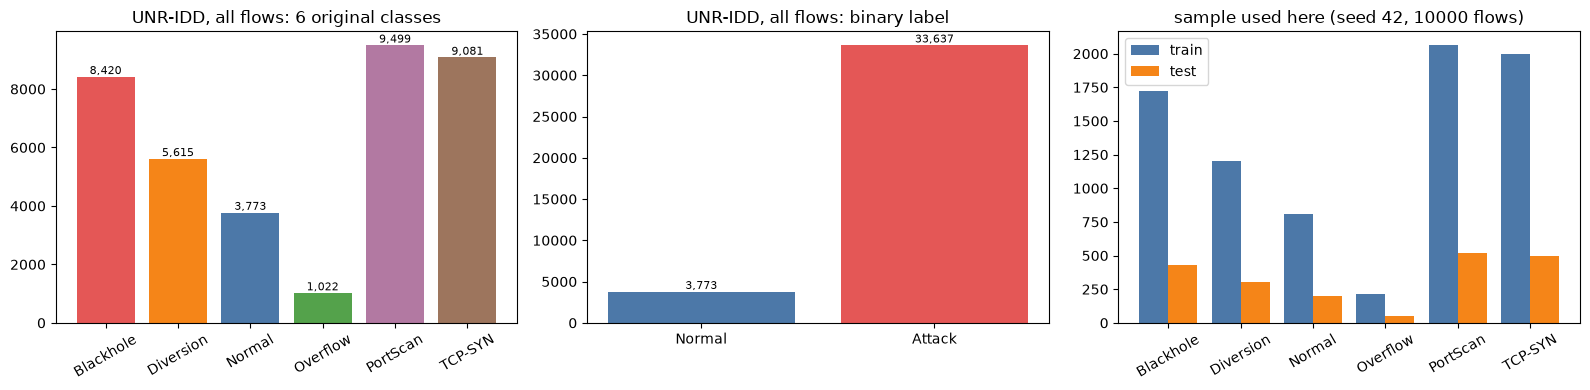

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
vc = DF_ALL["Label"].value_counts().reindex(CLASSES)
axes[0].bar(CLASSES, vc.values, color=[CLASS_COLORS[c] for c in CLASSES])
for i, v in enumerate(vc.values): axes[0].text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=8)
axes[0].set_title("UNR-IDD, all flows: 6 original classes"); axes[0].tick_params(axis="x", rotation=30)
vb = DF_ALL["Binary Label"].value_counts().reindex(["Normal", "Attack"])
axes[1].bar(vb.index, vb.values, color=["#4C78A8", "#E45756"])
for i, v in enumerate(vb.values): axes[1].text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=8)
axes[1].set_title("UNR-IDD, all flows: binary label")
xs = np.arange(len(CLASSES))
axes[2].bar(xs - 0.2, np.bincount(P0["y_m"][P0["itr"]], minlength=6), 0.4, label="train", color="#4C78A8")
axes[2].bar(xs + 0.2, np.bincount(P0["y_m"][P0["ite"]], minlength=6), 0.4, label="test", color="#F58518")
axes[2].set_xticks(xs); axes[2].set_xticklabels(CLASSES, rotation=30); axes[2].legend(); axes[2].set_title(f"sample used here (seed {SEEDS[0]}, {len(P0['X'])} flows)")
plt.tight_layout(); plt.show()

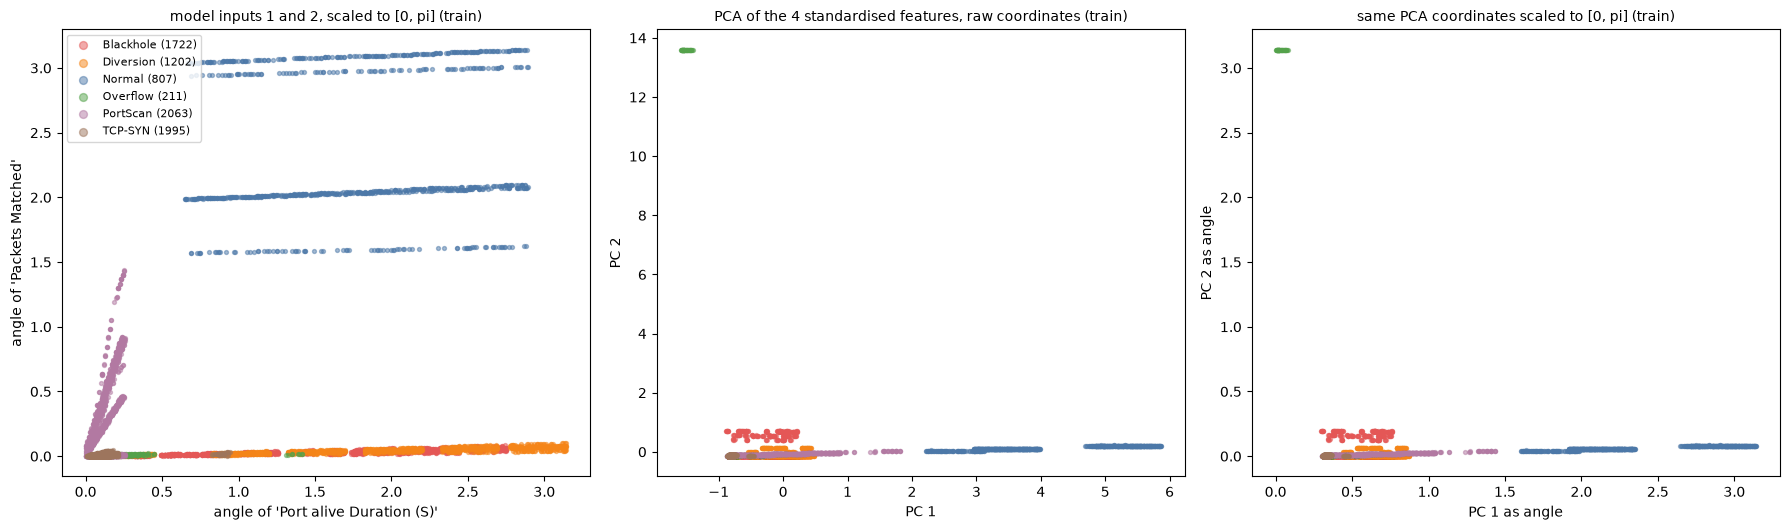

explained variance of the 2 PCA components: [0.54  0.249] | every point above is one real flow record coloured by its original 'Label'


In [10]:
p = P0; itr = p["itr"]
# (a) the four model inputs as the quantum circuits see them: angle scaling [0, pi], first two features, coloured by the original attack family
# (b) PCA of the four standardised training features (PCA fitted on the training split), raw coordinates, then the same coordinates scaled to [0, pi]
ss = StandardScaler().fit(p["X"][itr]); pca = PCA(n_components=2, random_state=SEED).fit(ss.transform(p["X"][itr]))
Ztr = pca.transform(ss.transform(p["X"][itr])); sc2 = MinMaxScaler((0, PI)).fit(Ztr); Ztr_pi = sc2.transform(Ztr)
labs = p["lab"][itr]
fig, axes = plt.subplots(1, 3, figsize=(18, 5.4))
for ax, M, names, ttl in [(axes[0], p["A_pi"][itr][:, :2], (f"angle of '{FEATURES[0]}'", f"angle of '{FEATURES[1]}'"), "model inputs 1 and 2, scaled to [0, pi] (train)"),
                          (axes[1], Ztr, ("PC 1", "PC 2"), "PCA of the 4 standardised features, raw coordinates (train)"),
                          (axes[2], Ztr_pi, ("PC 1 as angle", "PC 2 as angle"), "same PCA coordinates scaled to [0, pi] (train)")]:
    for c in CLASSES:
        m = labs == c
        ax.scatter(M[m, 0], M[m, 1], s=8, alpha=0.5, color=CLASS_COLORS[c], label=f"{c} ({m.sum()})")
    ax.set_xlabel(names[0]); ax.set_ylabel(names[1]); ax.set_title(ttl, fontsize=10)
axes[0].legend(markerscale=2, fontsize=8)
plt.tight_layout(); plt.show()
print("explained variance of the 2 PCA components:", np.round(pca.explained_variance_ratio_, 3), "| every point above is one real flow record coloured by its original 'Label'")

## 3. The classical baselines (paper, Table I)

RF, KNN, SVM and NN are trained on **exactly the four angle-scaled features the quantum models receive** (min-max to [0, pi], fitted on the training split). The paper gives no hyper-parameters for them: scikit-learn defaults are used
(`RandomForestClassifier(100)`, `KNeighborsClassifier()`, `SVC(rbf, C=1)`) and `MLPClassifier((64, 32))` for the NN. Binary: attack is the positive class; the macro-F1 averages the F1 of all classes (paper: "mean F1", undefined).

In [11]:
RES = []        # one row per (model, task, seed)
PRED = {}       # (model, task, seed) -> test predictions (for confusion matrices)

def score(y, pred, task):
    out = dict(acc=accuracy_score(y, pred), f1_macro=f1_score(y, pred, average="macro", zero_division=0))
    if task == "binary":
        pr, rc, f, _ = precision_recall_fscore_support(y, pred, average="binary", zero_division=0)
        out.update(prec=pr, rec=rc, f1_attack=f)
    return out

def record(model, task, seed, y, pred, secs, **extra):
    RES.append(dict(model=model, task=task, seed=seed, secs=secs, **score(y, pred, task), **extra)); PRED[(model, task, seed)] = np.asarray(pred)

def targets(p, task):
    return (p["y_b"], "binary") if task == "binary" else (p["y_m"], "multiclass")

TASKS = ["binary", "multiclass"]
CLASSICAL = {"RF": lambda s: RandomForestClassifier(100, random_state=s, n_jobs=1),
             "KNN": lambda s: KNeighborsClassifier(),                                    # k = 5 (sklearn default)
             "SVM": lambda s: SVC(kernel="rbf", C=1.0, random_state=s),
             "NN":  lambda s: MLPClassifier((64, 32), max_iter=300, random_state=s)}     # CHOICE: the paper gives no NN architecture here

t_all = time.perf_counter()
for seed in SEEDS:
    p = PREP[seed]
    for task in TASKS:
        y, _ = targets(p, task)
        for name, make in CLASSICAL.items():
            t0 = time.perf_counter(); clf = make(seed).fit(p["A_pi"][p["itr"]], y[p["itr"]])      # same [0, pi] inputs as QSVM / QNN / HQNN
            pred = clf.predict(p["A_pi"][p["ite"]]); record(f"classical {name}", task, seed, y[p["ite"]], pred, time.perf_counter() - t0)
CLS = pd.DataFrame(RES)
print(f"classical baselines done in {time.perf_counter() - t_all:.0f} s")
print(CLS.pivot_table(index="model", columns="task", values=["acc", "f1_macro"], aggfunc="mean").round(4).to_string())

classical baselines done in 184 s


                 acc            f1_macro           
task          binary multiclass   binary multiclass
model                                              
classical KNN    1.0     0.8328      1.0     0.7893
classical NN     1.0     0.7990      1.0     0.7434
classical RF     1.0     0.9060      1.0     0.8780
classical SVM    1.0     0.7080      1.0     0.6480


## 4. A fast exact simulator, asserted equal to the Qiskit circuits

Training a QNN with 600 COBYLA evaluations on 8,000 flows, or an HQNN for 50 epochs (about 6,000 optimiser steps), with Qiskit's `SamplerQNN` would need millions of circuit executions (and the parameter-shift rule twice the number of trainable parameters per sample).
The circuits have only four qubits, so their state is a vector of 16 complex numbers. `CircuitSim` below is a small **PyTorch state-vector simulator that reads the gate list of the transpiled Qiskit circuit** (`rx, ry, rz, p, cx, h, x, s, sdg, z`) and applies it,
with one angle per sample for the feature map (which has no trainable parameter and is evaluated once) and tensors with gradients for the trainable part. For an exact simulator, autograd gives the same gradient as the parameter-shift rule;
the next section asserts both facts (engine == Qiskit `Statevector`, autograd Jacobian == parameter-shift Jacobian) for every QNN/HQNN circuit.

In [12]:
from qiskit.circuit import ParameterExpression
C128 = torch.complex128
BASIS = ["rx", "ry", "rz", "p", "cx", "h", "x", "s", "sdg", "z"]
_SQ2 = math.sqrt(2.0)
_FIXED = {"h": torch.tensor([[1, 1], [1, -1]], dtype=C128) / _SQ2, "x": torch.tensor([[0, 1], [1, 0]], dtype=C128),
          "z": torch.tensor([[1, 0], [0, -1]], dtype=C128), "s": torch.tensor([[1, 0], [0, 1j]], dtype=C128),
          "sdg": torch.tensor([[1, 0], [0, -1j]], dtype=C128)}

def _gate_matrix(name, a):
    """2x2 (or Bx2x2 when the angle is a vector of B angles) matrix of a one-qubit gate; differentiable in the angle."""
    if name in _FIXED: return _FIXED[name]
    a = torch.as_tensor(a, dtype=torch.float64)
    c, s = torch.cos(a / 2).to(C128), torch.sin(a / 2).to(C128)
    zero, one = torch.zeros_like(c), torch.ones_like(c)
    if name == "rx":  m = [[c, -1j * s], [-1j * s, c]]
    elif name == "ry": m = [[c, -s], [s, c]]
    elif name == "rz": m = [[torch.exp(-0.5j * a), zero], [zero, torch.exp(0.5j * a)]]
    elif name == "p":  m = [[one, zero], [zero, torch.exp(1j * a)]]
    else: raise ValueError(name)
    return torch.stack([torch.stack(r, -1) for r in m], -2)

class CircuitSim:
    """Exact state-vector simulator of a (parameterised) Qiskit circuit written in PyTorch.
    It reads the gate list of the transpiled Qiskit circuit, so it executes the same gates as the circuit that is drawn; angles can be
    tensors (a different angle per sample) and gradients flow through them (autograd == parameter-shift for exact simulation)."""
    def __init__(self, qc):
        self.n, self.D = qc.num_qubits, 2 ** qc.num_qubits
        t = transpile(qc, basis_gates=BASIS, optimization_level=0)
        self.params = list(qc.parameters); self.ops = []
        for inst in t.data:
            name = inst.operation.name
            if name in ("barrier", "measure"): continue
            qs = [t.find_bit(q).index for q in inst.qubits]; ang = None; perm = None
            if inst.operation.params:
                a = inst.operation.params[0]
                if isinstance(a, ParameterExpression):
                    expr = a.sympify(); by_name = {s.name: s for s in expr.free_symbols}
                    ps = sorted(a.parameters, key=lambda q: q.name)
                    ang = (sympy.lambdify([by_name[q.name] for q in ps], expr, modules="math"), ps)
                else: ang = float(a)
            if name == "cx":
                c, tg = qs; perm = torch.tensor([s ^ (1 << tg) if (s >> c) & 1 else s for s in range(self.D)])
            self.ops.append((name, qs, ang, perm))
        self.count = {k: sum(1 for o in self.ops if o[0] == k) for k in sorted({o[0] for o in self.ops})}

    def _apply1(self, psi, M, q):
        B, n = psi.shape[0], self.n; ax = n - q
        x = torch.movedim(psi.reshape(B, *([2] * n)), ax, -1); shp = x.shape; x = x.reshape(B, -1, 2)
        out = x @ M.T if M.dim() == 2 else torch.einsum("bij,bmj->bmi", M, x)
        return torch.movedim(out.reshape(shp), -1, ax).reshape(B, -1)

    def run(self, psi, values=None):
        """Apply the circuit to a batch of states psi (B, 2^n) (row = one state); values: {Parameter: scalar or (B,) tensor}."""
        for name, qs, ang, perm in self.ops:
            if name == "cx": psi = psi[:, perm]; continue
            if ang is None: a = None
            elif isinstance(ang, float): a = ang
            else: fn, ps = ang; a = fn(*[values[q] for q in ps])
            psi = self._apply1(psi, _gate_matrix(name, a) if a is not None else _FIXED[name], qs[0])
        return psi

    def unitary_T(self, values):
        """U^T (rows = images of the basis states) so that psi_out = psi_in @ U^T for row-vector states."""
        return self.run(torch.eye(self.D, dtype=C128), values)

def outcome_index(n, kept):
    """Map each basis state to the integer formed by the measured qubits (Qiskit convention: first measured qubit = least significant bit)."""
    return torch.tensor([sum(((s >> q) & 1) << i for i, q in enumerate(kept)) for s in range(2 ** n)])

def marginal(psi, idx, m):
    p = psi.real ** 2 + psi.imag ** 2
    return torch.zeros(psi.shape[0], 2 ** m, dtype=torch.float64).index_add_(1, idx, p)

print("CircuitSim ready (PyTorch state-vector engine that executes the gate list of a transpiled Qiskit circuit).")

CircuitSim ready (PyTorch state-vector engine that executes the gate list of a transpiled Qiskit circuit).


## Quantum Circuit Architecture

Every gate-based quantum model of the notebook is listed with the circuit that is **executed**: one drawing per distinct architecture, plus qubit count, depth and number of trainable parameters.

| Model | Circuit | Qubits | Trainable parameters |
|---|---|---|---|
| QNN, HQNN (binary and multiclass, two combinations each) | feature map -> ansatz (4 reps) -> two-qubit pooling -> measurement | 4 | 29 to 49 (binary), 23 to 43 (multiclass); the HQNN adds a classical head |
| QKNN-V1 (angle) | H, `U(a1', a2')` and `U(b1', b2')`, controlled-SWAP, H, measure ancilla | 3 | 0 |
| QKNN-V1 (amplitude) | H, amplitude-encoded `psi` (3 qubits) and `phi` (1 qubit), controlled-SWAP, H | 5 | 0 |
| QKNN-V2 | H, two `U` rotations per state, two controlled-SWAPs, H | 5 | 0 |
| QKNN-V3 | index superposition, oracle `W`, swap test, Grover iteration | 13 | 0 |
| QKNN-V3, idealised | index superposition, phase oracle on the K nearest, Grover diffusion | 8 | 0 |
| QSVM | `U(x_i)` followed by `U^dagger(x_j)`, measure P(0000) | 4 | 0 (the SVM weights are classical) |

**Assumptions where the paper omits circuit details.**
* Fig. 2 (the "slightly modified" ZZFeatureMap of the QSVM) and Fig. 4 (the pooling circuit) are graphics that cannot be read from the extracted text. The standard `ZZFeatureMap` (2 reps, full entanglement) and the two-qubit pooling circuit of the Qiskit QCNN tutorial are used instead and are marked as such.
* The feature maps use the library default of 2 repetitions; the ansatz uses the 4 repetitions of Figs. 5 and 6. With the default Paulis `['Z', 'ZZ']` a `PauliFeatureMap` is **the same circuit** as a `ZZFeatureMap`.
* Pooling: binary pools qubits (0 -> 2) and (1 -> 3), then (2 -> 3) and measures qubit 3; multiclass pools (0 -> 1) and measures qubits 1, 2, 3. The pooled-away qubit is simply not measured.
* QKNN-V1 (amplitude): the swap test is performed between the first qubit of the 3-qubit state `psi` and the 1-qubit state `phi`, which gives `<phi|rho|phi> = |a - b|^2 / (2Z)` and hence `D = |a - b|^2`, as in the paper's formula.
* QKNN-V3: the paper's Fig. 4 of Basheer et al. is not reproduced in the text; the circuit below is our reconstruction (see the choices table). The oracle `W` is a 1024 x 1024 unitary and is drawn as one box; the 8-qubit idealised variant uses a diagonal phase oracle.

Equivalence checks are in the code cells: the PyTorch engine equals Qiskit's `Statevector` to 1e-13, its autograd Jacobian equals the parameter-shift Jacobian to 1e-15, a shot-based `SamplerQNN` agrees within sampling error, the swap-test circuits equal their closed forms to 1e-9 on real flow pairs,
and the PennyLane feature map equals Qiskit's `ZZFeatureMap`.

In [13]:
def build_arch(fm_kind, ans_kind, task):
    """QNN / HQNN circuit: feature map -> ansatz -> quantum pooling -> measurement of the surviving qubits (binary: 1 qubit, multiclass: 3 qubits)."""
    n = 4
    if fm_kind == "zz": fm = zz_feature_map(n, reps=FM_REPS)
    else:               fm = pauli_feature_map(n, reps=FM_REPS, paulis=["Z", "ZZ"])      # CHOICE: library default Paulis (same circuit as the ZZ map, see text)
    ans = efficient_su2(n, reps=ANSATZ_REPS) if ans_kind == "su2" else real_amplitudes(n, reps=ANSATZ_REPS)
    layers = [([0, 1], [2, 3]), ([2], [3])] if task == "binary" else [([0], [1])]            # (sources, sinks): the source qubit is discarded after pooling
    kept = [3] if task == "binary" else [1, 2, 3]
    pv = ParameterVector("p", 3 * sum(len(s) for s, _ in layers))
    wc = QuantumCircuit(n); wc.compose(ans, inplace=True); k = 0
    for src, snk in layers:
        for s_, t_ in zip(src, snk):                       # two-qubit pooling circuit of the Qiskit QCNN tutorial (3 parameters)
            wc.rz(-math.pi / 2, t_); wc.cx(t_, s_); wc.rz(pv[k], s_); wc.ry(pv[k + 1], t_); wc.cx(s_, t_); wc.ry(pv[k + 2], t_); k += 3
        wc.barrier()
    m = len(kept)
    full = QuantumCircuit(n, m); full.compose(fm, inplace=True); full.compose(wc, inplace=True); full.measure(kept, range(m))
    w_params = list(ans.parameters) + list(pv)
    return dict(name=f"{'ZZFeatureMap' if fm_kind == 'zz' else 'PauliFeatureMap'} + {'EfficientSU2' if ans_kind == 'su2' else 'RealAmplitudes'} ({task})",
                fm_kind=fm_kind, ans_kind=ans_kind, task=task, fm=fm, ans=ans, wc=wc, full=full, kept=kept, m=m,
                x_params=list(fm.parameters), w_params=w_params, n_w=len(w_params),
                sim_fm=CircuitSim(fm), sim_w=CircuitSim(wc), idx=outcome_index(n, kept))

ARCH = {(fk, ak, task): build_arch(fk, ak, task) for task in TASKS for fk, ak in [("zz", "su2"), ("pauli", "ra")]}

_FMS = {}
def fm_states(arch, p):
    """Feature-map states |phi(x)> for ALL samples of a prepared split (no trainable parameter -> computed once)."""
    key = (p["seed"], arch["fm_kind"], len(p["X"]))
    if key not in _FMS:
        A = torch.as_tensor(p["A_pi"], dtype=torch.float64); psi0 = torch.zeros(len(A), 16, dtype=C128); psi0[:, 0] = 1
        _FMS[key] = arch["sim_fm"].run(psi0, {q: A[:, i] for i, q in enumerate(arch["x_params"])})
    return _FMS[key]

def arch_probs(arch, psi_x, w):
    UT = arch["sim_w"].unitary_T({q: w[i] for i, q in enumerate(arch["w_params"])})
    return marginal(psi_x @ UT, arch["idx"], arch["m"])

                                      circuit  qubits  measured qubits  depth (transpiled)  trainable parameters  of which pooling                                                                 gate counts
         ZZFeatureMap + EfficientSU2 (binary)       4                1                  60                    49                 9 {'cx': 42, 'ry': 26, 'rz': 26, 'p': 20, 'h': 8, 'barrier': 2, 'measure': 1}
    PauliFeatureMap + RealAmplitudes (binary)       4                1                  55                    29                 9  {'cx': 42, 'ry': 26, 'p': 20, 'h': 8, 'rz': 6, 'barrier': 2, 'measure': 1}
     ZZFeatureMap + EfficientSU2 (multiclass)       4                3                  56                    43                 3 {'cx': 38, 'ry': 22, 'rz': 22, 'p': 20, 'h': 8, 'measure': 3, 'barrier': 1}
PauliFeatureMap + RealAmplitudes (multiclass)       4                3                  51                    23                 3  {'cx': 38, 'ry': 22, 'p': 20, 'h': 8, 'm

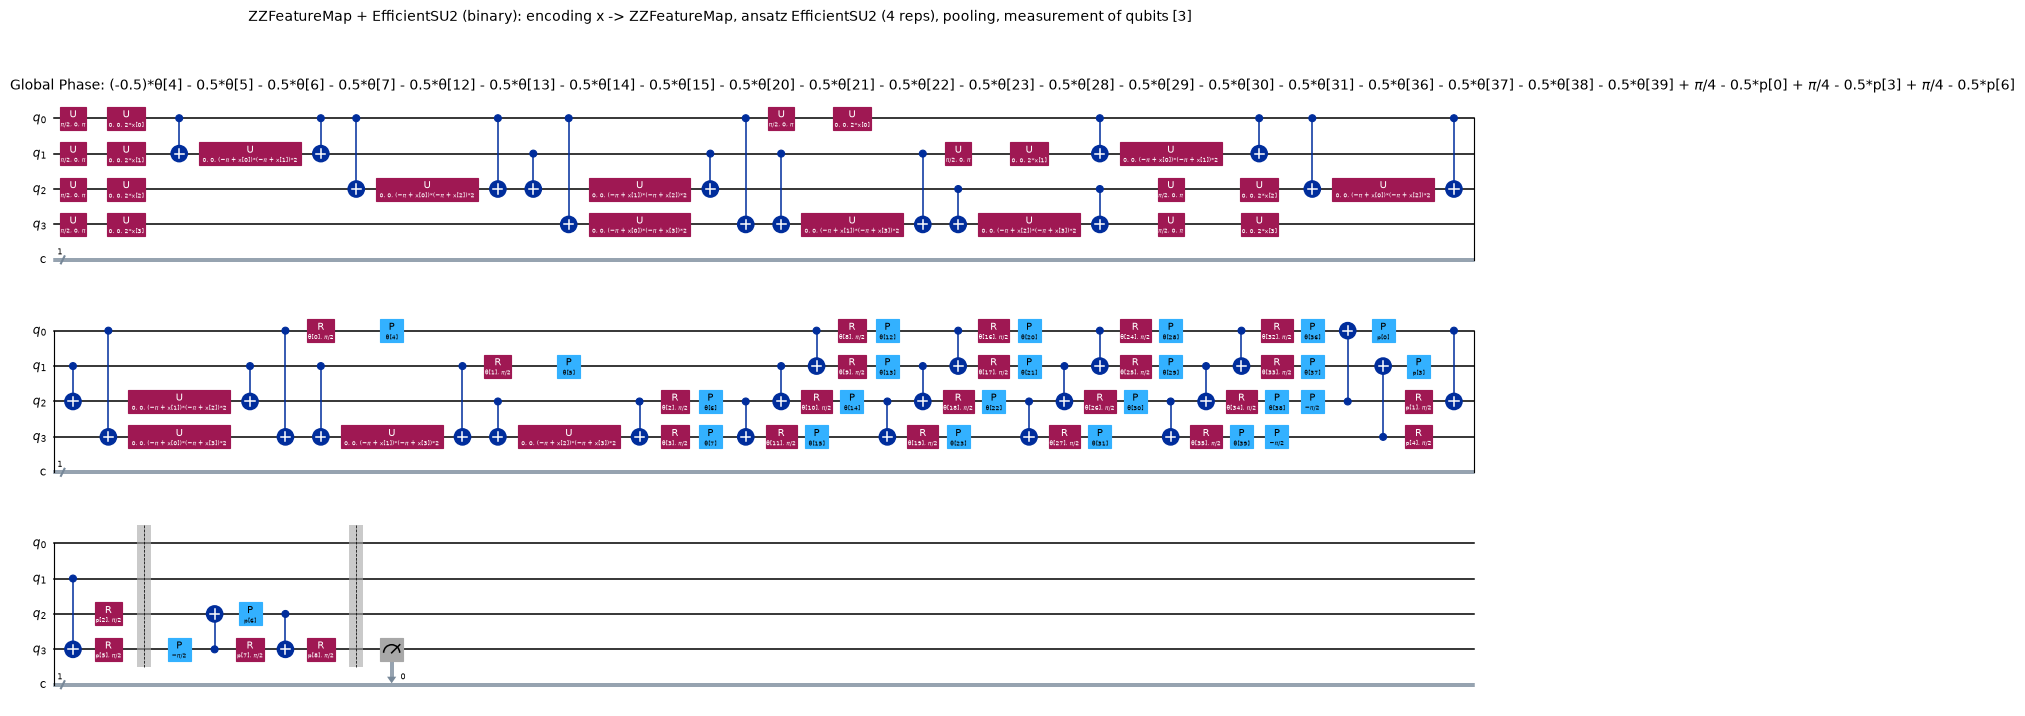

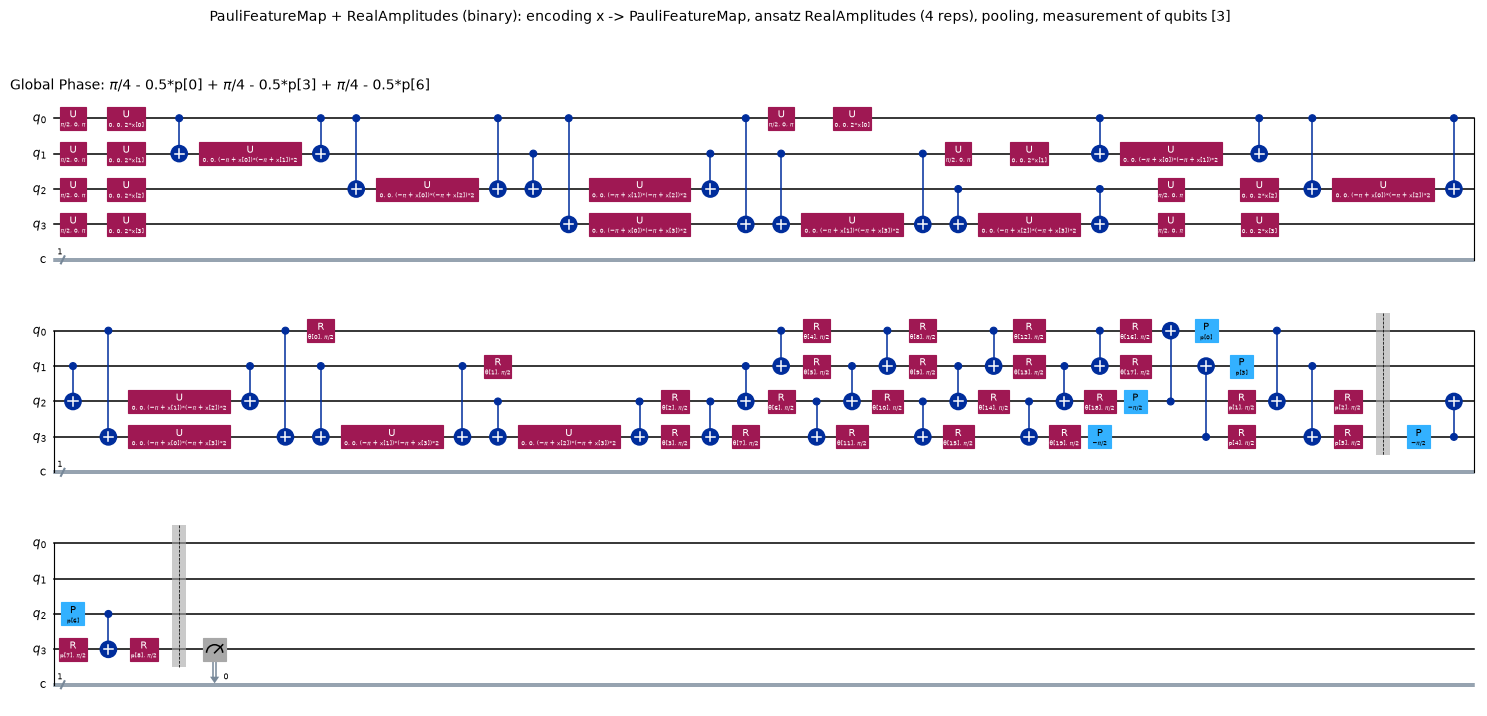

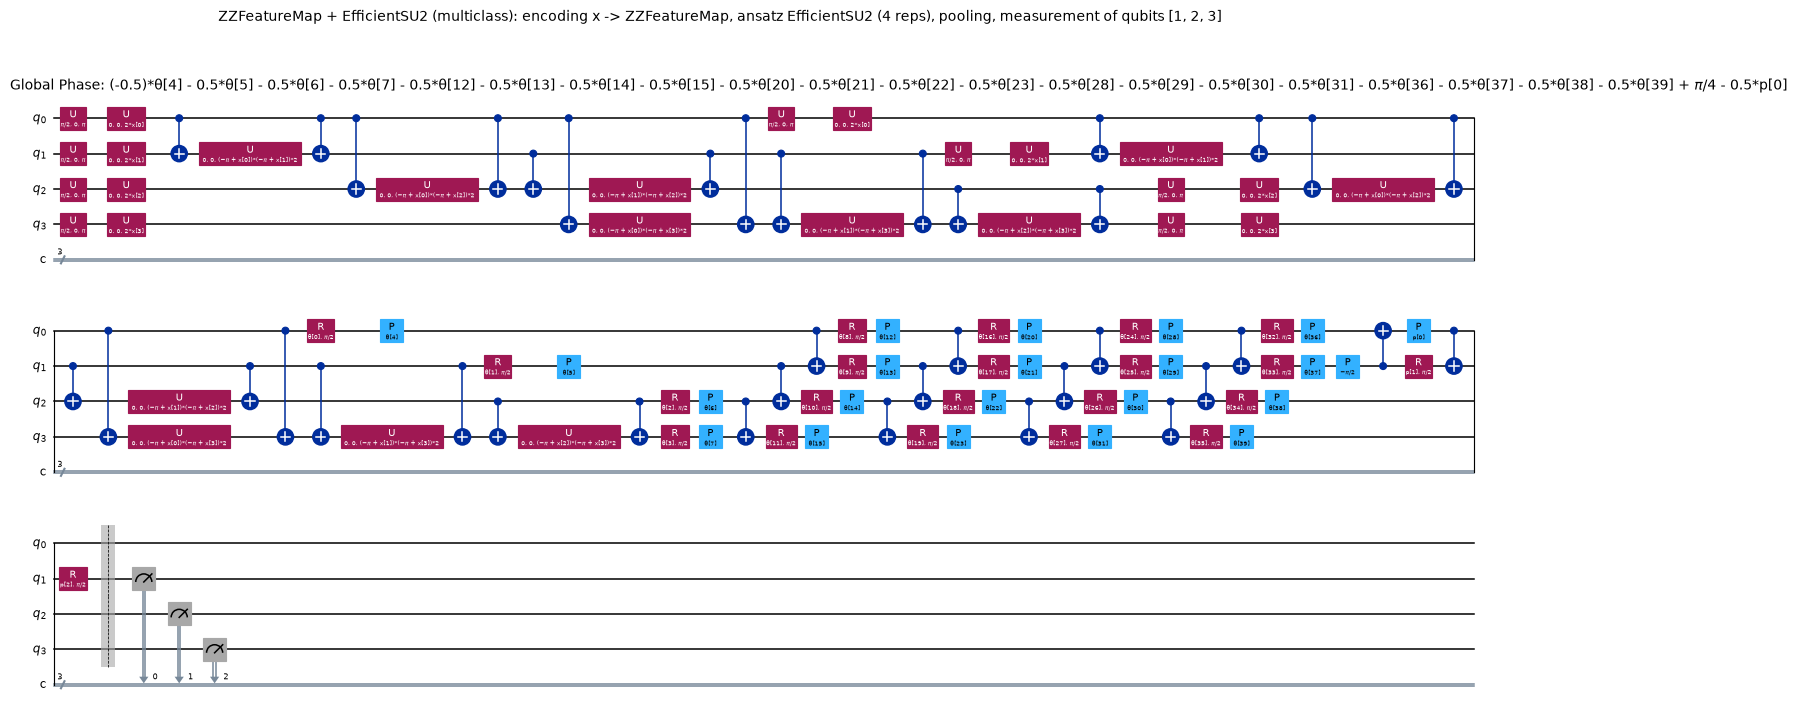

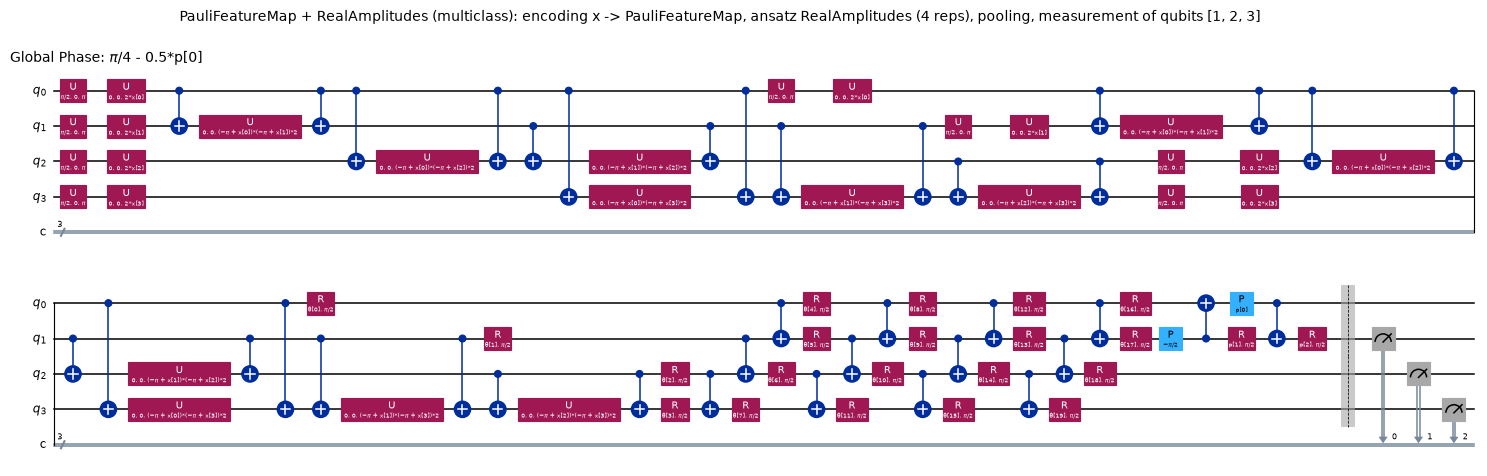

ZZFeatureMap + EfficientSU2 (binary)                         engine vs Qiskit Statevector: max |dp| = 2.2e-14 | autograd vs parameter-shift Jacobian: max |d| = 5.0e-16


PauliFeatureMap + RealAmplitudes (binary)                    engine vs Qiskit Statevector: max |dp| = 1.6e-14 | autograd vs parameter-shift Jacobian: max |d| = 5.6e-16


ZZFeatureMap + EfficientSU2 (multiclass)                     engine vs Qiskit Statevector: max |dp| = 3.4e-14 | autograd vs parameter-shift Jacobian: max |d| = 2.6e-16


PauliFeatureMap + RealAmplitudes (multiclass)                engine vs Qiskit Statevector: max |dp| = 2.2e-14 | autograd vs parameter-shift Jacobian: max |d| = 2.5e-16


Qiskit SamplerQNN (40,000 shots) vs exact engine: max |difference| = 0.0039


In [14]:
QNN_STATS = []
for key, a in ARCH.items():
    tq = transpile(a["full"], basis_gates=BASIS + ["measure"], optimization_level=0)
    QNN_STATS.append({"circuit": a["name"], "qubits": a["full"].num_qubits, "measured qubits": a["m"], "depth (transpiled)": tq.depth(),
                      "trainable parameters": a["n_w"], "of which pooling": a["n_w"] - a["ans"].num_parameters, "gate counts": dict(tq.count_ops())})
print(pd.DataFrame(QNN_STATS).to_string(index=False))
print("\nNote: with the library default Paulis ['Z','ZZ'] the PauliFeatureMap is the same circuit as the ZZFeatureMap, so the two combinations differ only in the ansatz.")

# One drawing per distinct architecture: the circuit that is executed (decomposed one level so that the feature map, the ansatz and the pooling are visible).
for task in TASKS:
    for fk, ak in [("zz", "su2"), ("pauli", "ra")]:
        a = ARCH[(fk, ak, task)]
        fig = a["full"].decompose().draw("mpl", fold=40, scale=0.55)
        fig.suptitle(f"{a['name']}: encoding x -> {a['fm'].name}, ansatz {a['ans'].name} (4 reps), pooling, measurement of qubits {a['kept']}", fontsize=10)
        show_fig(fig)

# ---- equivalence checks: the PyTorch engine executes the same circuit as Qiskit ----
from qiskit_machine_learning.neural_networks import SamplerQNN
from qiskit.primitives import StatevectorSampler
r_ = np.random.default_rng(SEED); A5 = P0["A_pi"][:5]
for key, a in ARCH.items():
    w = torch.as_tensor(r_.uniform(-np.pi, np.pi, a["n_w"]), dtype=torch.float64)
    mine = arch_probs(a, fm_states(a, P0)[:5], w).numpy()
    nm = a["full"].remove_final_measurements(inplace=False); ref = []
    for x in A5:
        bound = nm.assign_parameters({**dict(zip(a["x_params"], x)), **dict(zip(a["w_params"], w.numpy()))})
        ref.append(Statevector(bound).probabilities(qargs=a["kept"]))
    err = np.abs(mine - np.array(ref)).max(); assert err < 1e-9, err
    # parameter-shift rule == autograd for this exact simulator (the paper trains the quantum layer with the parameter-shift rule)
    psi = fm_states(a, P0)[:20]; eye = torch.eye(a["n_w"], dtype=torch.float64)
    pr = lambda ww: arch_probs(a, psi, ww)                                                   # output probabilities, (batch, outcomes)
    pr_grad = torch.stack([(pr(w + (np.pi / 2) * eye[i]) - pr(w - (np.pi / 2) * eye[i])) / 2 for i in range(a["n_w"])])     # parameter-shift rule
    jac_auto = torch.autograd.functional.jacobian(pr, w)                                     # autograd, (batch, outcomes, n_w)
    err_g = (jac_auto.permute(2, 0, 1) - pr_grad).abs().max().item(); assert err_g < 1e-9, err_g
    print(f"{a['name']:60s} engine vs Qiskit Statevector: max |dp| = {err:.1e} | autograd vs parameter-shift Jacobian: max |d| = {err_g:.1e}")

# the Qiskit SamplerQNN of the paper itself (shot-based sampler) agrees with the exact engine within sampling error
a = ARCH[("zz", "su2", "binary")]; w = torch.as_tensor(r_.uniform(-np.pi, np.pi, a["n_w"]), dtype=torch.float64)
try:
    qnn = SamplerQNN(circuit=a["full"], input_params=a["x_params"], weight_params=a["w_params"],
                     sampler=StatevectorSampler(default_shots=40000, seed=SEED))
    out = np.vstack([qnn.forward(x[None], w.numpy()) for x in A5])     # one sample per call: in qiskit-machine-learning 0.9.1 a batched forward returned identical rows with StatevectorSampler
    mine = arch_probs(a, fm_states(a, P0)[:5], w).numpy()
    out = out[:, :mine.shape[1]]            # SamplerQNN reserves 2^n_qubits outputs; only the measured outcomes are non-zero
    print("Qiskit SamplerQNN (40,000 shots) vs exact engine: max |difference| =", round(float(np.abs(out - mine).max()), 4))
    assert np.abs(out - mine).max() < 0.02
except Exception as e:
    print("SamplerQNN check skipped:", type(e).__name__, e)

12 real pairs: swap-test circuits == closed forms (angle: P(1) = 1/2 - 1/2 |<psi|phi>|^2; amplitude: P(0) = 1/2 + |a-b|^2/(4Z), D = |a-b|^2)  -> assertion passed


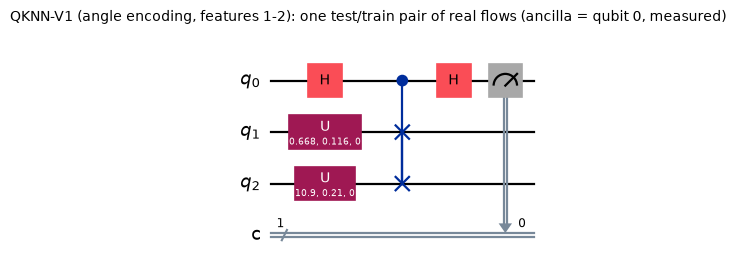

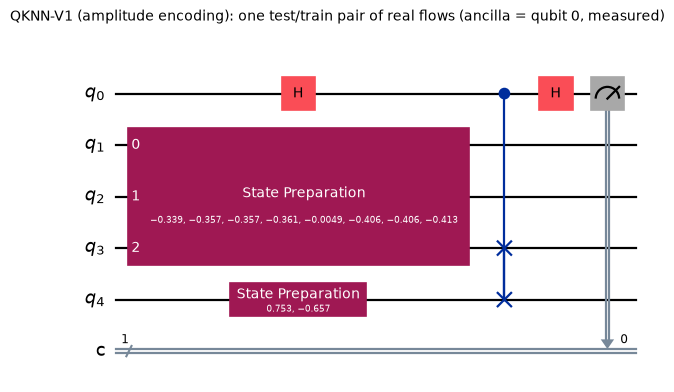

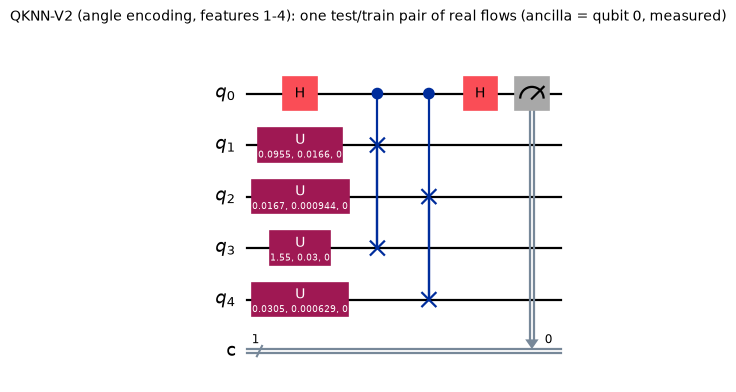

                               circuit  qubits  depth (decomposed)  trainable parameters                                      gates
QKNN-V1 (angle encoding, features 1-2)       3                   4                     0 {'h': 2, 'u': 2, 'cswap': 1, 'measure': 1}
          QKNN-V1 (amplitude encoding)       5                  20                     0  {'u': 15, 'cx': 12, 'h': 4, 'measure': 1}
QKNN-V2 (angle encoding, features 1-4)       5                   5                     0 {'u': 4, 'h': 2, 'cswap': 2, 'measure': 1}


In [15]:
SQ2 = math.sqrt(2.0)

# ---- closed forms of the swap-test statistics (used for the 16 million test x train pairs; the circuits below are used to prove they are exact) ----
def single_qubit_overlap(thA, gA, thB, gB):
    """|<psi|phi>|^2 for |psi> = U(thA, gA)|0> and |phi> = U(thB, gB)|0>, with U(theta, gamma)|0> = (cos(theta/2), exp(i gamma) sin(theta/2))  (paper, Eq. 1)."""
    c = np.cos(thA / 2) * np.cos(thB / 2) + np.exp(1j * (gB - gA)) * np.sin(thA / 2) * np.sin(thB / 2)
    return np.abs(c) ** 2

def angle_overlap(Aa, Bb, factor, n_states):
    """Overlap of the angle-encoded states of feature vectors Aa (T,4) and Bb (N,4) (both in [-1,1]) -> (T,N). n_states = 1: QKNN-V1 (features 1,2 only), 2: QKNN-V2 (all four)."""
    a_, b_ = factor * (Aa + 1), factor * (Bb + 1); ov = 1.0
    for j in range(n_states):
        ov = ov * single_qubit_overlap(a_[:, None, 2 * j], a_[:, None, 2 * j + 1], b_[None, :, 2 * j], b_[None, :, 2 * j + 1])
    return ov

def amplitude_overlap(Aa, Bb):
    """<phi|rho|phi> of the amplitude-encoding swap test = |a - b|^2 / (2 Z),  Z = |a|^2 + |b|^2  (Lloyd / Diadamo construction)."""
    na, nb = (Aa ** 2).sum(1)[:, None], (Bb ** 2).sum(1)[None, :]
    d2 = na + nb - 2 * Aa @ Bb.T
    return np.clip(d2 / (2 * (na + nb) + 1e-12), 0, 1), na + nb

# ---- the circuits that are executed (one numeric pair of real flows each) ----
def circuit_knn_angle(a4, b4, factor, n_states):
    nq = 1 + 2 * n_states; qc = QuantumCircuit(nq, 1); a_, b_ = factor * (np.asarray(a4) + 1), factor * (np.asarray(b4) + 1)
    qc.h(0)
    for j in range(n_states):
        qc.u(a_[2 * j], a_[2 * j + 1], 0, 1 + j)                       # |psi> = U(a'_{2j+1}, a'_{2j+2})|0>   (u(theta, phi, 0) = Eq. 1)
        qc.u(b_[2 * j], b_[2 * j + 1], 0, 1 + n_states + j)            # |phi> = U(b'_{2j+1}, b'_{2j+2})|0>
    for j in range(n_states): qc.cswap(0, 1 + j, 1 + n_states + j)
    qc.h(0); qc.measure(0, 0)
    return qc

def circuit_knn_amplitude(a4, b4):
    a4, b4 = np.asarray(a4, float), np.asarray(b4, float); na, nb = np.linalg.norm(a4), np.linalg.norm(b4); Z = na ** 2 + nb ** 2
    psi = np.concatenate([a4 / na, b4 / nb]) / SQ2                      # (|0>|a^> + |1>|b^>)/sqrt2 on qubits 1,2 (data) and 3 (the 0/1 qubit)
    phi = np.array([na, -nb]) / math.sqrt(Z)                            # (|a||0> - |b||1>)/sqrt(Z) on qubit 4
    qc = QuantumCircuit(5, 1); qc.h(0)
    qc.append(StatePreparation(psi), [1, 2, 3]); qc.append(StatePreparation(phi), [4])
    qc.cswap(0, 3, 4); qc.h(0); qc.measure(0, 0)
    return qc

def p_anc(qc, outcome):
    """Exact probability of the ancilla outcome (0 or 1) of one of the circuits above."""
    return float(Statevector(qc.remove_final_measurements(inplace=False)).probabilities([0])[outcome])

# ---- equivalence of circuits and closed forms on real pairs ----
Ap = P0["A_pm"]; rr = np.random.default_rng(SEED); pairs = rr.integers(0, len(Ap), (12, 2))
for (i, j) in pairs:
    a, b = Ap[i], Ap[j]
    for name, factor, ns in [("V1 angle", V1_ANGLE_FACTOR, 1), ("V2", V2_ANGLE_FACTOR, 2)]:
        ov = angle_overlap(a[None], b[None], factor, ns)[0, 0]
        assert abs(p_anc(circuit_knn_angle(a, b, factor, ns), 1) - (0.5 - 0.5 * ov)) < 1e-9
    s, Z = amplitude_overlap(a[None], b[None])
    assert abs(p_anc(circuit_knn_amplitude(a, b), 0) - (0.5 + 0.5 * s[0, 0])) < 1e-9
    assert abs(4 * Z[0, 0] * (p_anc(circuit_knn_amplitude(a, b), 0) - 0.5) - ((a - b) ** 2).sum()) < 1e-9       # D = 4Z(P(0) - 1/2) is the squared Euclidean distance
print("12 real pairs: swap-test circuits == closed forms (angle: P(1) = 1/2 - 1/2 |<psi|phi>|^2; amplitude: P(0) = 1/2 + |a-b|^2/(4Z), D = |a-b|^2)  -> assertion passed")

i0, j0 = pairs[0]; ex_a, ex_b = Ap[i0], Ap[j0]
QKNN_CIRCUITS = {"QKNN-V1 (angle encoding, features 1-2)": circuit_knn_angle(ex_a, ex_b, V1_ANGLE_FACTOR, 1),
                 "QKNN-V1 (amplitude encoding)": circuit_knn_amplitude(ex_a, ex_b),
                 "QKNN-V2 (angle encoding, features 1-4)": circuit_knn_angle(ex_a, ex_b, V2_ANGLE_FACTOR, 2)}
rows = []
for name, qc in QKNN_CIRCUITS.items():
    t_ = transpile(qc, basis_gates=["u", "cx", "h", "cswap", "measure"] if "amplitude" not in name else ["u", "cx", "h", "measure"], optimization_level=0)
    rows.append({"circuit": name, "qubits": qc.num_qubits, "depth (decomposed)": t_.depth(), "trainable parameters": 0, "gates": dict(t_.count_ops())})
    fig = qc.draw("mpl", scale=0.8); fig.suptitle(f"{name}: one test/train pair of real flows (ancilla = qubit 0, measured)", fontsize=10); show_fig(fig)
print(pd.DataFrame(rows).to_string(index=False))

QKNN-V3 circuit: 13 qubits (1 ancilla + 2 test + 2 train + 8 index); trainable parameters: 0
  A: 8 instructions, depth 5 counting the 8-qubit state preparation and the 1024x1024 oracle W as single boxes; gates: {'u': 2, 'h': 2, 'cswap': 2, 'state_preparation': 1, 'unitary': 1}


  G (one Grover iteration): depth 18; for this real test flow P(ancilla = 0) after A is 0.859, so the rule for the number of Grover iterations gives k = 0; executed circuit A + 0 x G has depth 5 (W would cost on the order of 4^10 CNOTs if synthesised)


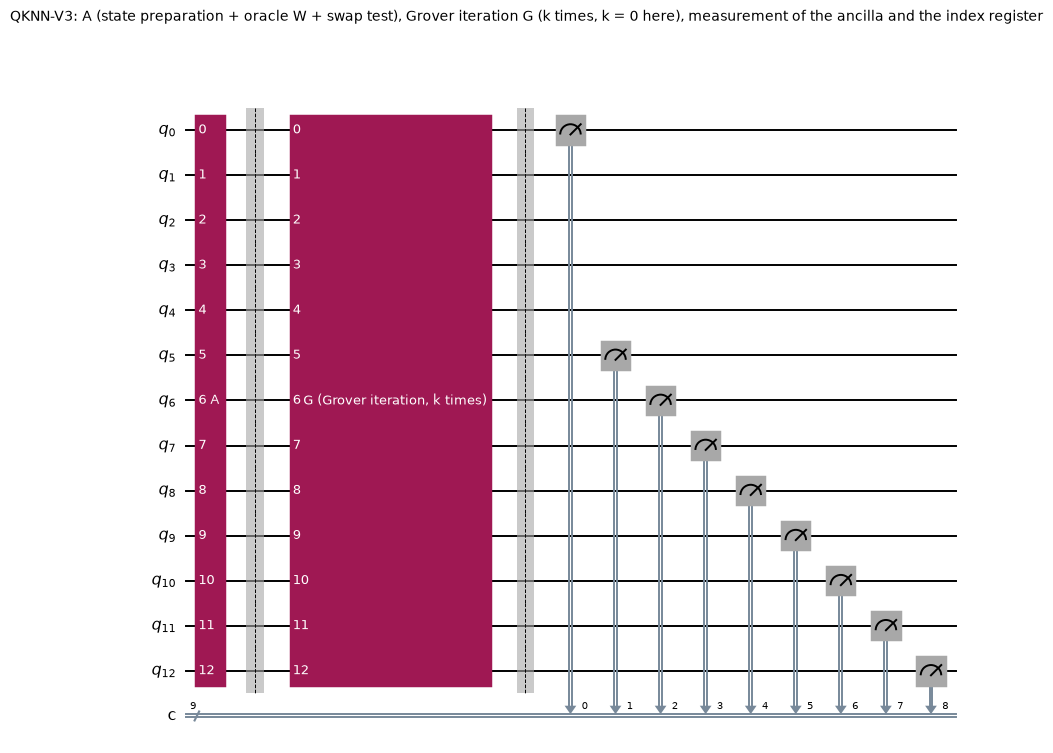

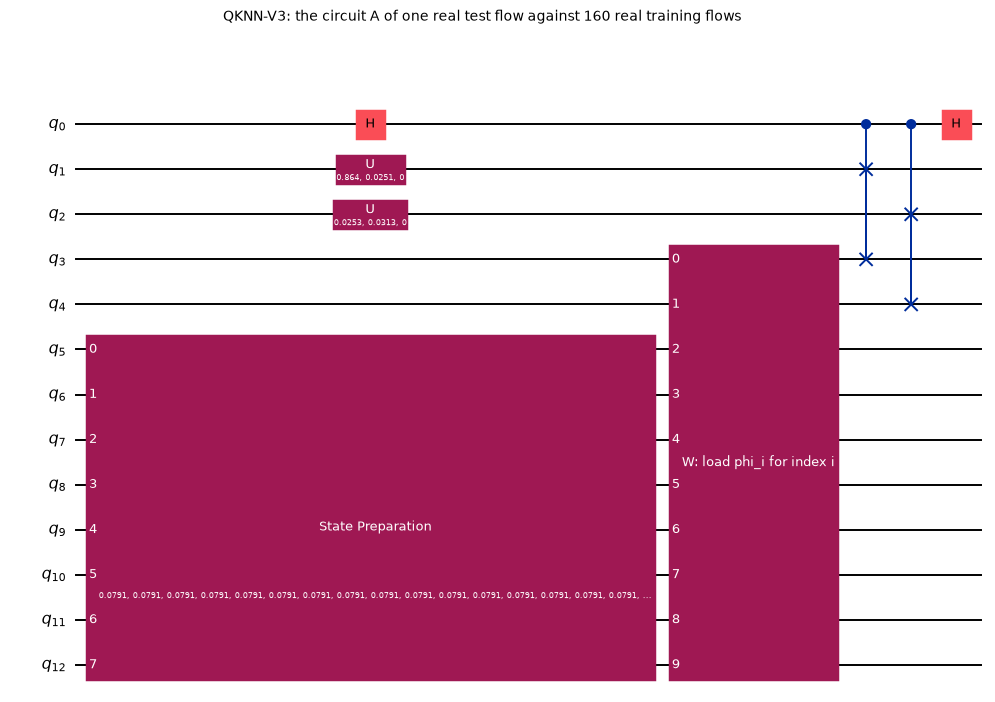

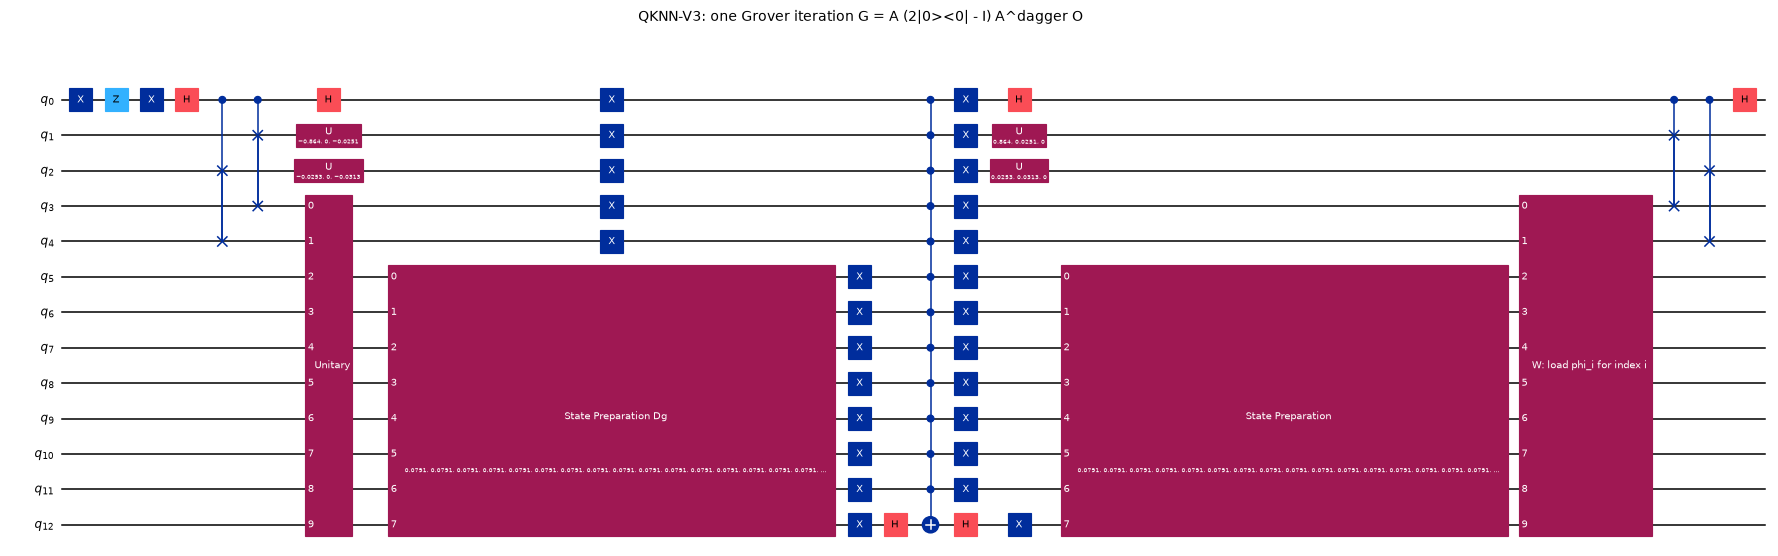

idealised QKNN-V3: 8 qubits, 4 Grover iterations, depth 33, trainable parameters: 0


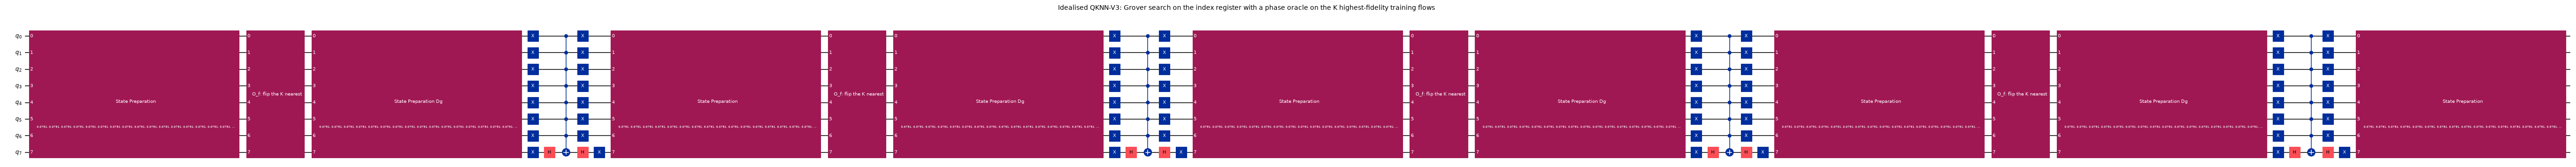

checked: swap test inside A gives P(ancilla = 0) = mean_i (1 + F_i)/2 and P(i | ancilla = 0) proportional to (1 + F_i); the cached-prefix simulation equals Statevector(A); the linear-algebra Grover equals the Qiskit circuit of the idealised variant (all to 1e-9)


In [16]:
def v3_sample(seed):
    """The 200-flow sample of QKNN-V3 (80 % train / 20 % test), features scaled to [-1, 1] on the training part only."""
    d = DF_ALL.sample(n=N_V3, random_state=seed).reset_index(drop=True)
    X = d[FEATURES].to_numpy(float); y_m = np.array([CLASSES.index(v) for v in d["Label"]]); y_b = (y_m != NORMAL_ID).astype(int)
    try: itr, ite = train_test_split(np.arange(N_V3), test_size=TEST_SIZE, stratify=y_m, random_state=seed)
    except ValueError: itr, ite = train_test_split(np.arange(N_V3), test_size=TEST_SIZE, random_state=seed)      # a class with a single member cannot be stratified
    sc = MinMaxScaler((-1, 1)).fit(X[itr]); A = np.clip(sc.transform(X), -1, 1)
    return dict(seed=seed, A=A, y_m=y_m, y_b=y_b, itr=itr, ite=ite)

def u1_matrix(t, g):
    return np.array([[np.cos(t / 2), -np.sin(t / 2)], [np.exp(1j * g) * np.sin(t / 2), np.exp(1j * g) * np.cos(t / 2)]])      # paper Eq. (1)

# QKNN-V3 (our reconstruction of Basheer et al.). Qubit layout: 0 = ancilla, 1-2 = test state, 3-4 = train register, 5... = index register.
def v3_layout(n_tr):
    m = max(1, math.ceil(math.log2(n_tr))); return m, [1, 2], [3, 4], list(range(5, 5 + m)), 5 + m

_W_CACHE, _PREFIX = {}, {}
def v3_prefix_circuit(A_tr):
    """Index register in uniform superposition over the training flows, then the oracle W|0>|i> = |phi_i>|i> (a block-diagonal unitary, one box)."""
    n_tr = len(A_tr); m, tq, rq, iq, nq = v3_layout(n_tr); th = V2_ANGLE_FACTOR * (A_tr + 1)
    key = hash(A_tr.tobytes())
    if key not in _W_CACHE:       # W depends on the training flows only: build it once per split
        blocks = [np.kron(u1_matrix(th[i, 2], th[i, 3]), u1_matrix(th[i, 0], th[i, 1])) for i in range(n_tr)] + [np.eye(4)] * (2 ** m - n_tr)
        _W_CACHE[key] = block_diag(*blocks)
    amp = np.zeros(2 ** m); amp[:n_tr] = 1 / math.sqrt(n_tr)
    P = QuantumCircuit(nq, name="prefix")
    P.append(StatePreparation(amp), iq)                                       # (1/sqrt(N)) sum_i |i>
    P.append(UnitaryGate(_W_CACHE[key], label="W: load phi_i for index i"), rq + iq)
    return P, key

def v3_test_circuit(a_test, n_tr):
    """Test state |phi_test> = U(b1',b2') (x) U(b3',b4')|00> and the swap test against the train register."""
    m, tq, rq, iq, nq = v3_layout(n_tr); tb = V2_ANGLE_FACTOR * (np.asarray(a_test) + 1)
    T = QuantumCircuit(nq, name="test + swap test")
    T.u(tb[0], tb[1], 0, tq[0]); T.u(tb[2], tb[3], 0, tq[1])
    T.h(0); T.cswap(0, tq[0], rq[0]); T.cswap(0, tq[1], rq[1]); T.h(0)           # swap test: P(ancilla = 0 | i) = (1 + F_i) / 2
    return T

def build_v3_circuits(A_tr, a_test):
    """A = prefix + test + swap test; G = one Grover iteration that amplifies the ancilla-0 ('similar') branch."""
    n_tr = len(A_tr); m, tq, rq, iq, nq = v3_layout(n_tr)
    P, _ = v3_prefix_circuit(A_tr); T = v3_test_circuit(a_test, n_tr)
    A = QuantumCircuit(nq, name="A"); A.compose(P, inplace=True); A.compose(T, inplace=True)
    G = QuantumCircuit(nq, name="G")
    G.x(0); G.z(0); G.x(0)                                                    # oracle: phase flip of the 'similar' branch (ancilla = 0)
    G.compose(A.inverse(), inplace=True)
    G.x(range(nq)); G.h(nq - 1); G.mcx(list(range(nq - 1)), nq - 1); G.h(nq - 1); G.x(range(nq))      # reflection about |0...0>
    G.compose(A, inplace=True)
    return A, G, iq, m

def grover_iterations(a_marked):
    """Number of Grover iterations. Amplitude amplification of a marked branch of probability a = sin^2(theta) gives sin^2((2k + 1) theta).
    For a < 1/2 the usual k = round(pi / (4 theta) - 1/2) is used. For a >= 1/2 (theta >= 45 degrees) the first iteration already overshoots
    (sin^2(3 theta) < a) and the probability only comes back after many rotations, so k = 0 is used.
    CHOICE: the paper does not say how many iterations are used; in hardware a would have to be estimated by quantum counting."""
    th_ = math.asin(math.sqrt(min(max(a_marked, 1e-12), 1.0)))
    return 0 if a_marked >= 0.5 else max(0, int(round(math.pi / (4 * th_) - 0.5)))

def v3_run(A_tr, a_test, rng_, shots=SHOTS_V3):
    """Exact state-vector simulation of A (+ k Grover iterations), then 2048 shots on (ancilla, index); the shots with ancilla 0 are kept."""
    n_tr = len(A_tr); m, tq, rq, iq, nq = v3_layout(n_tr); P, key = v3_prefix_circuit(A_tr)
    if key not in _PREFIX: _PREFIX[key] = Statevector(P)                      # the prefix does not depend on the test flow: simulated once per split
    sv = _PREFIX[key].evolve(v3_test_circuit(a_test, n_tr)); a_marked = float(sv.probabilities([0])[0])
    k = V3_GROVER_ITERATIONS if V3_GROVER_ITERATIONS is not None else grover_iterations(a_marked)
    if k:
        _, G, _, _ = build_v3_circuits(A_tr, a_test)
        for _ in range(k): sv = sv.evolve(G)
    # The index register alone is uniform whatever the swap test does (the test acts on the ancilla), so the ancilla is measured together with the index
    # and only the shots with ancilla = 0 ('similar' branch) are kept: P(i | ancilla = 0) is proportional to (1 + F_i) after A.
    pj = sv.probabilities([0] + iq)                                           # outcome value = ancilla + 2 * index
    pidx = pj[0::2][:n_tr]; pidx = pidx / pidx.sum()                          # exact distribution of the index given ancilla = 0
    counts_all = rng_.multinomial(shots, pj / pj.sum())                       # finite-shot measurement of the paper's simulator
    return pidx, counts_all[0::2][:n_tr], k, a_marked

# ---- idealised variant: Grover search on the index register with a phase oracle on the K highest-fidelity training flows ----
def build_v3_ideal(marked, n_tr):
    """The comparator that would mark the K nearest training flows is not described in the paper; here its phase oracle is evaluated from the exact fidelities."""
    m = max(1, math.ceil(math.log2(n_tr))); amp = np.zeros(2 ** m); amp[:n_tr] = 1 / math.sqrt(n_tr)
    prep = QuantumCircuit(m, name="S"); prep.append(StatePreparation(amp), range(m))
    diag = np.ones(2 ** m); diag[list(marked)] = -1
    k = max(1, int(round(math.pi / 4 * math.sqrt(n_tr / len(marked)) - 0.5)))
    qc = QuantumCircuit(m); qc.compose(prep, inplace=True)
    for _ in range(k):
        qc.append(UnitaryGate(np.diag(diag), label="O_f: flip the K nearest"), range(m))
        qc.compose(prep.inverse(), inplace=True); qc.x(range(m)); qc.h(m - 1); qc.mcx(list(range(m - 1)), m - 1); qc.h(m - 1); qc.x(range(m)); qc.compose(prep, inplace=True)
    return qc, k, m

def ideal_distribution(marked, n_tr, k):
    """The same Grover iterations in plain linear algebra (asserted equal to the Qiskit circuit below): oracle = sign flip, diffusion = 2|s><s| - 1."""
    s = np.zeros(2 ** max(1, math.ceil(math.log2(n_tr)))); s[:n_tr] = 1 / math.sqrt(n_tr); psi = s.copy()
    for _ in range(k):
        psi[list(marked)] *= -1; psi = 2 * s * (s @ psi) - psi
    p = psi[:n_tr] ** 2; return p / p.sum()

def v3_ideal_run(A_tr, a_test, rng_, shots=SHOTS_V3):
    fid = angle_overlap(np.asarray(a_test)[None], A_tr, V2_ANGLE_FACTOR, 2)[0]; marked = np.argsort(-fid)[:K_NEIGHBOURS]
    k = max(1, int(round(math.pi / 4 * math.sqrt(len(A_tr) / len(marked)) - 0.5)))
    pidx = ideal_distribution(marked, len(A_tr), k)
    return pidx, rng_.multinomial(shots, pidx), k

# ---- draw the circuits that are executed, for a real test flow ----
sv3 = v3_sample(SEEDS_V3[0]); A_tr3, A_te3 = sv3["A"][sv3["itr"]], sv3["A"][sv3["ite"]]
A_c, G_c, iq_c, m_c = build_v3_circuits(A_tr3, A_te3[0]); nq3 = A_c.num_qubits
a_ex = float(Statevector(A_c).probabilities([0])[0]); k_ex = V3_GROVER_ITERATIONS if V3_GROVER_ITERATIONS is not None else grover_iterations(a_ex)
tot_c = A_c.copy()
for _ in range(k_ex): tot_c.compose(G_c, inplace=True)
print(f"QKNN-V3 circuit: {nq3} qubits (1 ancilla + 2 test + 2 train + {m_c} index); trainable parameters: 0")
print(f"  A: {len(A_c.data)} instructions, depth {A_c.depth()} counting the {m_c}-qubit state preparation and the {2 ** (2 + m_c)}x{2 ** (2 + m_c)} oracle W as single boxes; gates: {dict(A_c.count_ops())}")
print(f"  G (one Grover iteration): depth {G_c.depth()}; for this real test flow P(ancilla = 0) after A is {a_ex:.3f}, so the rule for the number of Grover iterations gives k = {grover_iterations(a_ex)}; "
      f"executed circuit A + {k_ex} x G has depth {tot_c.depth()} (W would cost on the order of 4^10 CNOTs if synthesised)")
blocks_fig = QuantumCircuit(nq3, m_c + 1)
blocks_fig.append(A_c.to_gate(label="A"), range(nq3)); blocks_fig.barrier()
blocks_fig.append(G_c.to_gate(label="G (Grover iteration, k times)"), range(nq3)); blocks_fig.barrier(); blocks_fig.measure([0] + iq_c, range(m_c + 1))
fig = blocks_fig.draw("mpl", fold=-1, scale=0.7); fig.suptitle("QKNN-V3: A (state preparation + oracle W + swap test), Grover iteration G (k times, k = 0 here), measurement of the ancilla and the index register", fontsize=10); show_fig(fig)
fig = A_c.draw("mpl", fold=-1, scale=0.7); fig.suptitle("QKNN-V3: the circuit A of one real test flow against 160 real training flows", fontsize=10); show_fig(fig)
fig = G_c.draw("mpl", fold=-1, scale=0.55); fig.suptitle("QKNN-V3: one Grover iteration G = A (2|0><0| - I) A^dagger O", fontsize=10); show_fig(fig)
fid_ex = angle_overlap(A_te3[:1], A_tr3, V2_ANGLE_FACTOR, 2)[0]
marked_ex = np.argsort(-fid_ex)[:K_NEIGHBOURS]
ideal_c, k_id, m_id = build_v3_ideal(marked_ex, len(A_tr3))
print(f"idealised QKNN-V3: {m_id} qubits, {k_id} Grover iterations, depth {ideal_c.depth()}, trainable parameters: 0")
fig = ideal_c.draw("mpl", fold=-1, scale=0.55); fig.suptitle("Idealised QKNN-V3: Grover search on the index register with a phase oracle on the K highest-fidelity training flows", fontsize=10); show_fig(fig)
# ---- equivalences ----
assert abs(a_ex - (1 + fid_ex).mean() / 2) < 1e-9, (a_ex, ((1 + fid_ex) / 2).mean())
pj_full = Statevector(A_c).probabilities([0] + iq_c); p_idx_full = pj_full[0::2][:len(A_tr3)]; p_idx_full = p_idx_full / p_idx_full.sum()
assert np.allclose(p_idx_full, (1 + fid_ex) / (1 + fid_ex).sum(), atol=1e-9)
p_run, _, _, _ = v3_run(A_tr3, A_te3[0], np.random.default_rng(0)); assert np.allclose(p_run, p_idx_full, atol=1e-9)
assert np.allclose(ideal_distribution(marked_ex, len(A_tr3), k_id), (lambda q: q[:len(A_tr3)] / q[:len(A_tr3)].sum())(Statevector(ideal_c).probabilities()), atol=1e-9)
print("checked: swap test inside A gives P(ancilla = 0) = mean_i (1 + F_i)/2 and P(i | ancilla = 0) proportional to (1 + F_i); the cached-prefix simulation equals Statevector(A); "
      "the linear-algebra Grover equals the Qiskit circuit of the idealised variant (all to 1e-9)")

PennyLane feature map == Qiskit ZZFeatureMap (fidelity 1 up to 1e-9); kernel from states == kernel circuit U^dagger(x_j) U(x_i) (6 x 6 Gram matrix, 1e-10)


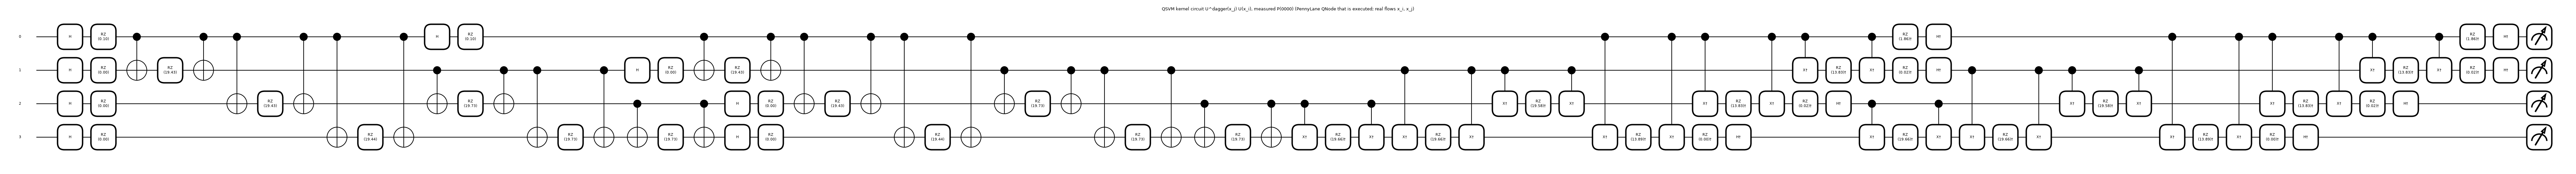

QSVM kernel circuit: 4 qubits, depth 62, trainable parameters: 0 (the SVM weights alpha are classical), gates: {'Hadamard': 8, 'RZ': 20, 'CNOT': 24, 'Adjoint(CNOT)': 24, 'Adjoint(RZ)': 20, 'Adjoint(Hadamard)': 8}


In [17]:
N_Q = 4
dev_k = qml.device("default.qubit", wires=N_Q)

def zz_map(x, reps=2):
    """The ZZFeatureMap (full entanglement) written with H, RZ and CNOT gates. P(phi) = exp(i phi/2) RZ(phi), so RZ differs from Qiskit's P only by a global phase.
    The paper uses a 'slightly modified' version with X and RZ gates (its Figure 2 is not machine-readable): that modification is not known, this is the library circuit."""
    for _ in range(reps):
        for i in range(N_Q):
            qml.Hadamard(wires=i); qml.RZ(2 * x[..., i], wires=i)
        for i, j in itertools.combinations(range(N_Q), 2):
            qml.CNOT(wires=[i, j]); qml.RZ(2 * (math.pi - x[..., i]) * (math.pi - x[..., j]), wires=j); qml.CNOT(wires=[i, j])

@qml.qnode(dev_k)
def kernel_circuit(x1, x2):
    zz_map(x1); qml.adjoint(zz_map)(x2)               # U^dagger(x_j) U(x_i)|0000>
    return qml.probs(wires=range(N_Q))                # kernel entry K(x_i, x_j) = P(0000)

@qml.qnode(dev_k)
def state_circuit(x):
    zz_map(x)
    return qml.state()

# ---- equivalence: PennyLane map == Qiskit ZZFeatureMap; batched states == the kernel circuit ----
xa, xb = P0["A_pi"][0], P0["A_pi"][1]
sv_qiskit = Statevector(zz_feature_map(N_Q, reps=2, entanglement="full").assign_parameters(xa)).data
sv_pl = np.asarray(state_circuit(xa)).reshape([2] * N_Q).transpose(*range(N_Q - 1, -1, -1)).reshape(-1)       # PennyLane is big-endian, Qiskit little-endian
assert abs(abs(np.vdot(sv_qiskit, sv_pl)) - 1) < 1e-9
S2 = np.asarray(state_circuit(P0["A_pi"][:6]))                      # parameter broadcasting: one state per row
K_states = np.abs(S2 @ S2.conj().T) ** 2
K_circ = np.array([[float(kernel_circuit(P0["A_pi"][i], P0["A_pi"][j])[0]) for j in range(6)] for i in range(6)])
assert np.allclose(K_states, K_circ, atol=1e-10)
print("PennyLane feature map == Qiskit ZZFeatureMap (fidelity 1 up to 1e-9); kernel from states == kernel circuit U^dagger(x_j) U(x_i) (6 x 6 Gram matrix, 1e-10)")

fig, ax = qml.draw_mpl(kernel_circuit, decimals=2, fontsize=8, style="black_white", wire_order=range(N_Q))(xa, xb)
fig.suptitle("QSVM kernel circuit U^dagger(x_j) U(x_i), measured P(0000) (PennyLane QNode that is executed; real flows x_i, x_j)", fontsize=9); show_fig(fig)
sp = qml.specs(kernel_circuit, level="device")(xa, xb)
res_ = sp.resources if hasattr(sp, "resources") else sp["resources"]
print(f"QSVM kernel circuit: {N_Q} qubits, depth {res_.depth if hasattr(res_, 'depth') else res_['depth']}, trainable parameters: 0 (the SVM weights alpha are classical), gates: {dict(res_.gate_types if hasattr(res_, 'gate_types') else res_['gate_types'])}")

## 5. Quantum k-nearest neighbours: QKNN-V1 and QKNN-V2

The distance between a test flow and a training flow is estimated by a swap-test-like circuit run for **2048 shots**; a k-nearest-neighbour vote (k = 5, `KNeighborsClassifier` semantics) then classifies the test flow. Evaluating the circuit for every one of the
2,000 x 8,000 pairs in Qiskit would take days, so the notebook uses the closed forms of the circuits' ancilla probabilities that the previous section proved exact on real flow pairs, and **draws the 2048-shot statistics from the binomial distribution**, which is exactly what 2048 runs of the circuit return.

* **V1 angle**: `D = sqrt(Z P(1))`, `P(1) = 1/2 - 1/2 |<psi|phi>|^2`, states from features 1 and 2 only, angles `7*pi/2 * (a + 1)`.
* **V1 amplitude**: `D = 4Z(P(0) - 1/2)` (the squared Euclidean distance); shot noise can make it negative, such values are clipped to 0.
* **V2**: `D = sqrt(Z P(1))` with all four features on two qubits per state, angles `pi/2 * (a + 1)`.

`Z = |a|^2 + |b|^2` is computed from the [-1, 1]-scaled feature vectors. Shot noise creates many exact ties (probabilities of 0 give `D = 0`); ties are broken at random. The ablations (first seed) show the effect of noise (exact probabilities) and of the angle factor of V1.

In [18]:
from scipy.spatial.distance import cdist

def knn_vote(D, ytr, k, n_classes):
    """k nearest neighbours from a (test x train) distance matrix, majority vote, ties -> smallest label (like sklearn)."""
    idx = np.argpartition(D, k - 1, axis=1)[:, :k]
    labs = ytr[idx]
    return np.stack([(labs == c).sum(1) for c in range(n_classes)], 1).argmax(1)

# the paper uses KNeighborsClassifier() with the quantum inner products as distance; this helper is checked against it
r_ = np.random.default_rng(0); Xa, Xb, ya = r_.normal(size=(120, 4)), r_.normal(size=(40, 4)), r_.integers(0, 3, 120)
sk_pred = KNeighborsClassifier(n_neighbors=5, metric="precomputed").fit(cdist(Xa, Xa), ya).predict(cdist(Xb, Xa))
assert (sk_pred == knn_vote(cdist(Xb, Xa), ya, 5, 3)).all(); print("knn_vote == sklearn KNeighborsClassifier(metric='precomputed'): asserted")

def qknn_distances(variant, A_te, A_tr, rng_, shots, chunk=250, factor=None):
    """Distance matrix (test x train) of the QKNN swap-test circuits. shots=None: exact probabilities; otherwise the ancilla outcome is sampled
    binomially, which is exactly what `shots` runs of the circuit give (the circuit==closed-form equivalence was asserted above)."""
    out = np.empty((len(A_te), len(A_tr)), np.float32)
    for s in range(0, len(A_te), chunk):
        a = A_te[s:s + chunk]
        if variant == "amp":
            sq, Z = amplitude_overlap(a, A_tr); P0 = 0.5 + 0.5 * sq
            P0h = P0 if shots is None else rng_.binomial(shots, np.clip(P0, 0, 1)) / shots
            D = np.maximum(4 * Z * (P0h - 0.5), 0)                                        # D = 4Z(P(0) - 1/2); negative shot-noise values clipped to 0
        else:
            f, ns = (factor or V1_ANGLE_FACTOR, 1) if variant == "v1" else (V2_ANGLE_FACTOR, 2)
            P1 = 0.5 - 0.5 * angle_overlap(a, A_tr, f, ns)
            P1h = P1 if shots is None else rng_.binomial(shots, np.clip(P1, 0, 1)) / shots
            Z = (a ** 2).sum(1)[:, None] + (A_tr ** 2).sum(1)[None, :]
            D = np.sqrt(Z * P1h)                                                           # D = sqrt(Z P(1))
        if rng_ is not None: D = D + 1e-6 * rng_.random(D.shape)                           # CHOICE: random tie-breaking (shot noise creates many exact ties)
        out[s:s + chunk] = D
    return out

QKNN_VARIANTS = [("QKNN-V1 (angle)", "v1", None), ("QKNN-V1 (amplitude)", "amp", None), ("QKNN-V2", "v2", None)]
t_all = time.perf_counter()
for seed in SEEDS:
    p = PREP[seed]; itr, ite = p["itr"], p["ite"]; Atr, Ate = p["A_pm"][itr], p["A_pm"][ite]
    for name, var, f in QKNN_VARIANTS:
        rng_ = np.random.default_rng(seed); t0 = time.perf_counter()
        D = qknn_distances(var, Ate, Atr, rng_, SHOTS_KNN, factor=f); secs = time.perf_counter() - t0
        for task in TASKS:
            y, _ = targets(p, task); ncls = 2 if task == "binary" else len(CLASSES)
            record(name, task, seed, y[ite], knn_vote(D, y[itr], K_NEIGHBOURS, ncls), secs)
    print(f"seed {seed}: QKNN-V1 (angle / amplitude), V2 done, {time.perf_counter() - t0:.0f} s for the last variant, total {time.perf_counter() - t_all:.0f} s")

# ablations on the first seed: exact probabilities (infinite shots) and the angle factor of V1 (7pi/2 in the paper vs pi/2 of V2)
p = PREP[SEEDS[0]]; itr, ite = p["itr"], p["ite"]; Atr, Ate = p["A_pm"][itr], p["A_pm"][ite]
ABL = []
for name, var, f, shots in [("QKNN-V1 (angle), exact probabilities", "v1", None, None), ("QKNN-V1 (angle), factor pi/2", "v1", V2_ANGLE_FACTOR, SHOTS_KNN),
                            ("QKNN-V1 (amplitude), exact probabilities", "amp", None, None), ("QKNN-V2, exact probabilities", "v2", None, None)]:
    D = qknn_distances(var, Ate, Atr, np.random.default_rng(SEEDS[0]), shots, factor=f)
    for task in TASKS:
        y, _ = targets(p, task); ncls = 2 if task == "binary" else len(CLASSES)
        ABL.append(dict(variant=name, task=task, acc=accuracy_score(y[ite], knn_vote(D, y[itr], K_NEIGHBOURS, ncls))))
print("\nablations (first seed):"); print(pd.DataFrame(ABL).pivot(index="variant", columns="task", values="acc").round(4).to_string())
print(pd.DataFrame(RES).query("model.str.startswith('QKNN')").pivot_table(index="model", columns="task", values="acc", aggfunc="mean").round(4).to_string())

knn_vote == sklearn KNeighborsClassifier(metric='precomputed'): asserted


seed 42: QKNN-V1 (angle / amplitude), V2 done, 20 s for the last variant, total 49 s


seed 43: QKNN-V1 (angle / amplitude), V2 done, 42 s for the last variant, total 132 s


seed 44: QKNN-V1 (angle / amplitude), V2 done, 43 s for the last variant, total 236 s



ablations (first seed):
task                                      binary  multiclass
variant                                                     
QKNN-V1 (amplitude), exact probabilities   1.000      0.8335
QKNN-V1 (angle), exact probabilities       0.974      0.7600
QKNN-V1 (angle), factor pi/2               1.000      0.6315
QKNN-V2, exact probabilities               1.000      0.8365


task                 binary  multiclass
model                                  
QKNN-V1 (amplitude)   1.000      0.5125
QKNN-V1 (angle)       0.965      0.6505
QKNN-V2               1.000      0.7090


## 6. Quantum support vector machine (PennyLane)

The kernel `K(x_i, x_j) = |<0000|U^dagger(x_j) U(x_i)|0000>|^2` is computed analytically (the paper did not set a number of shots, so PennyLane ran its exact simulator). The Gram matrices (train x train, test x train) are built from the PennyLane **state** QNode
with parameter broadcasting (asserted equal to the kernel circuit above), and a classical `SVC(kernel="precomputed", C=1)` finishes the job. Features are scaled to [0, pi].

Extra row (not in the paper): the **kernel bandwidth**, i.e. a scale factor on all angles, is chosen from {0.25, 0.5, 1, 2} on a validation part of the training split (project convention: tune only on training data) and the SVM is refitted on the whole training split.

In [19]:
def qsvm_states(A, scale=1.0, chunk=2000):
    """Feature-map states U(scale * x)|0000> of all samples, computed with the PennyLane QNode (parameter broadcasting), as an (N, 16) complex array."""
    return np.concatenate([np.asarray(state_circuit(scale * A[i:i + chunk])) for i in range(0, len(A), chunk)])

def gram(S1, S2):
    return np.abs(S1 @ S2.conj().T) ** 2          # K(x_i, x_j) = |<0|U^dagger(x_j) U(x_i)|0>|^2, analytic (the paper did not set a shot number: "PennyLane performed an analytical execution")

def qsvm_predict(S, itr, ite, y, C):
    Ktr = gram(S[itr], S[itr]); Kte = gram(S[ite], S[itr])
    clf = SVC(kernel="precomputed", C=C).fit(Ktr, y[itr])
    return clf.predict(Kte)

SCALES = [0.25, 0.5, 1.0, 2.0]          # kernel bandwidth = angle scale; tuned on a validation split of the TRAINING data only (project convention)
QSVM_TUNE = []
t_all = time.perf_counter()
for seed in SEEDS:
    p = PREP[seed]; itr, ite = p["itr"], p["ite"]; A = p["A_pi"]
    S1 = qsvm_states(A)                                                              # scale 1: the paper's circuit
    for task in TASKS:
        y, _ = targets(p, task); t0 = time.perf_counter()
        pred = qsvm_predict(S1, itr, ite, y, QSVM_C); record("QSVM", task, seed, y[ite], pred, time.perf_counter() - t0)
    # bandwidth tuned on a validation split (extra row, not the paper's setting)
    states_by_scale = {1.0: S1}
    for sc in SCALES:
        if sc not in states_by_scale: states_by_scale[sc] = qsvm_states(A, sc)
    for task in TASKS:
        y, _ = targets(p, task); t0 = time.perf_counter()
        val = {sc: accuracy_score(y[p["iva"]], qsvm_predict(states_by_scale[sc], p["itr_sub"], p["iva"], y, QSVM_C)) for sc in SCALES}
        best = max(val, key=val.get); QSVM_TUNE.append(dict(seed=seed, task=task, **{f"val acc s={sc}": round(v, 4) for sc, v in val.items()}, chosen=best))
        pred = qsvm_predict(states_by_scale[best], itr, ite, y, QSVM_C); record("QSVM (bandwidth tuned)", task, seed, y[ite], pred, time.perf_counter() - t0, scale=best)
    print(f"seed {seed}: QSVM done, total {time.perf_counter() - t_all:.0f} s")
    del states_by_scale
print(pd.DataFrame(QSVM_TUNE).to_string(index=False))
print(pd.DataFrame(RES).query("model.str.startswith('QSVM')").pivot_table(index="model", columns="task", values="acc", aggfunc="mean").round(4).to_string())

seed 42: QSVM done, total 98 s


seed 43: QSVM done, total 186 s


seed 44: QSVM done, total 281 s
 seed       task  val acc s=0.25  val acc s=0.5  val acc s=1.0  val acc s=2.0  chosen
   42     binary          1.0000         1.0000         0.9990         0.9770    0.25
   42 multiclass          0.7085         0.7470         0.7725         0.7690    1.00
   43     binary          1.0000         1.0000         0.9995         0.9770    0.25
   43 multiclass          0.7140         0.7635         0.7845         0.7745    1.00
   44     binary          1.0000         1.0000         1.0000         0.9805    0.25
   44 multiclass          0.7090         0.7420         0.7645         0.7625    1.00
task                    binary  multiclass
model                                     
QSVM                       1.0      0.7828
QSVM (bandwidth tuned)     1.0      0.7828


## 7. Quantum neural network (Qiskit `SamplerQNN` semantics, COBYLA)

For each combination (feature map + ansatz) and task the circuit of the previous section is trained with **COBYLA for `COBYLA_ITERS` function evaluations** on the full training split (paper: 600). Binary: the loss is the L2 loss on the one-hot probability vector of the single measured qubit
(`qiskit-machine-learning`'s `L2Loss`); multiclass: cross-entropy on the 8 outcome probabilities of the 3 measured qubits, classes 0-5 being the targets. Prediction is the most probable outcome. The loss curve of every run is kept for the paper's Fig. 10.
Initial weights are uniform in [0, 1) (the default of `NeuralNetworkClassifier`). One run per seed.

In [20]:
COMBOS = [("zz", "su2"), ("pauli", "ra")]
COMBO_NAME = {("zz", "su2"): "ZZFeatureMap+EfficientSU2", ("pauli", "ra"): "PauliFeatureMap+RealAmplitudes"}
QNN_LOSS = {}          # (combo, task, seed) -> list of loss values (one per COBYLA function evaluation)

def qnn_loss(probs, y, task):
    if task == "binary":                                                  # L2 loss on one-hot targets (qiskit-machine-learning L2Loss)
        return ((probs - F.one_hot(y, 2).double()) ** 2).sum(1).mean()
    return -torch.log(probs[torch.arange(len(y)), y] + 1e-10).mean()      # cross-entropy on the 8 outcomes (classes 0-5 are targets; outcomes 6, 7 are never targets)

def train_qnn(arch, p, task, seed, iters):
    psi = fm_states(arch, p); y_all, _ = targets(p, task)
    psi_tr, ytr = psi[p["itr"]], torch.as_tensor(y_all[p["itr"]])
    w0 = np.random.default_rng(seed).random(arch["n_w"])                 # NeuralNetworkClassifier default: uniform [0, 1)
    hist = []
    def f(w):
        with torch.no_grad(): L = qnn_loss(arch_probs(arch, psi_tr, torch.as_tensor(w, dtype=torch.float64)), ytr, task).item()
        hist.append(L); return L
    res = minimize(f, w0, method="COBYLA", options=dict(maxiter=iters, rhobeg=1.0))     # COBYLA, `iters` function evaluations (paper: 600)
    w = torch.as_tensor(res.x, dtype=torch.float64)
    with torch.no_grad(): probs_te = arch_probs(arch, psi[p["ite"]], w)
    ncls = 2 if task == "binary" else len(CLASSES)
    return probs_te[:, :ncls].argmax(1).numpy(), hist, res.x

QNN_WEIGHTS = {}
t_all = time.perf_counter()
for seed in SEEDS:
    p = PREP[seed]
    for task in TASKS:
        y, _ = targets(p, task)
        for fk, ak in COMBOS:
            t0 = time.perf_counter(); arch = ARCH[(fk, ak, task)]
            pred, hist, w = train_qnn(arch, p, task, seed, COBYLA_ITERS); secs = time.perf_counter() - t0
            record(f"QNN {COMBO_NAME[(fk, ak)]}", task, seed, y[p["ite"]], pred, secs, final_loss=hist[-1]); QNN_LOSS[((fk, ak), task, seed)] = hist; QNN_WEIGHTS[((fk, ak), task, seed)] = w
            print(f"seed {seed} | {task:10s} | {COMBO_NAME[(fk, ak)]:32s} | loss {hist[0]:.3f} -> {hist[-1]:.3f} | test acc {accuracy_score(y[p['ite']], pred):.4f} | {secs:.0f} s")
print(f"QNN total {time.perf_counter() - t_all:.0f} s")

seed 42 | binary     | ZZFeatureMap+EfficientSU2        | loss 0.646 -> 0.103 | test acc 0.9415 | 40 s


seed 42 | binary     | PauliFeatureMap+RealAmplitudes   | loss 0.592 -> 0.124 | test acc 0.9380 | 28 s


seed 42 | multiclass | ZZFeatureMap+EfficientSU2        | loss 2.228 -> 1.344 | test acc 0.5220 | 42 s


seed 42 | multiclass | PauliFeatureMap+RealAmplitudes   | loss 2.545 -> 1.397 | test acc 0.5445 | 51 s


seed 43 | binary     | ZZFeatureMap+EfficientSU2        | loss 0.705 -> 0.113 | test acc 0.9395 | 48 s


...

seed 43 | multiclass | PauliFeatureMap+RealAmplitudes   | loss 2.379 -> 1.405 | test acc 0.4965 | 37 s


seed 44 | binary     | ZZFeatureMap+EfficientSU2        | loss 0.435 -> 0.123 | test acc 0.9475 | 61 s


seed 44 | binary     | PauliFeatureMap+RealAmplitudes   | loss 0.518 -> 0.131 | test acc 0.9290 | 26 s


seed 44 | multiclass | ZZFeatureMap+EfficientSU2        | loss 2.704 -> 1.336 | test acc 0.5270 | 36 s


seed 44 | multiclass | PauliFeatureMap+RealAmplitudes   | loss 2.294 -> 1.371 | test acc 0.4765 | 29 s
QNN total 483 s


## 8. Hybrid quantum-classical neural network (`TorchConnector` semantics)

The same quantum layers feed their outcome probabilities (2 values for the binary task, 8 for the multiclass task) into a classical head: two hidden layers (32 and 16 units, our choice) with batch normalisation, Leaky ReLU and dropout, then a single logit with binary cross-entropy (binary) or 6 logits with cross-entropy (multiclass).
Circuit weights and head weights are trained together with Adam (learning rate 0.01, batch 64, `HQNN_EPOCHS` epochs; paper: 50); the gradient of the circuit weights is the exact gradient of the simulator, which equals the parameter-shift gradient. As a control the same head is trained on the four angle-scaled features directly (no quantum layer).
Note that for the binary task the quantum layer passes **one number** (the probability of outcome 1) to the head, and for the multiclass task 8 numbers that sum to one.

In [21]:
def make_head(n_in, n_out):
    h1, h2 = HQNN_HIDDEN                                                   # two hidden layers with batch norm, Leaky ReLU and dropout (paper, Section III-D)
    return nn.Sequential(nn.Linear(n_in, h1), nn.BatchNorm1d(h1), nn.LeakyReLU(), nn.Dropout(HQNN_DROPOUT),
                         nn.Linear(h1, h2), nn.BatchNorm1d(h2), nn.LeakyReLU(), nn.Dropout(HQNN_DROPOUT), nn.Linear(h2, n_out))

class HQNN(nn.Module):
    """Quantum layer (feature map -> ansatz -> pooling -> outcome probabilities, exact simulation, trainable circuit parameters) followed by the classical head."""
    def __init__(self, arch, n_out, seed):
        super().__init__(); self.arch = arch
        g = torch.Generator().manual_seed(seed)
        self.w = nn.Parameter(torch.rand(arch["n_w"], generator=g, dtype=torch.float64) * 2 - 1)      # TorchConnector default: uniform [-1, 1)
        self.head = make_head(2 ** arch["m"], n_out)
    def forward(self, psi_x):
        return self.head(arch_probs(self.arch, psi_x, self.w).float())

class ClassicalNet(nn.Module):
    """Control: the same classical head fed with the 4 angle-scaled features directly (no quantum layer)."""
    def __init__(self, n_out):
        super().__init__(); self.head = make_head(4, n_out)
    def forward(self, x): return self.head(x.float())

def fit_hybrid(model, X_tr, y_tr, X_te, y_te, task, seed, epochs):
    torch.manual_seed(seed); g = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=HQNN_LR); n = len(X_tr)
    ytr = torch.as_tensor(y_tr); curves = []
    def predict(X):
        model.eval()
        with torch.no_grad(): o = model(X)
        return (o.squeeze(-1) > 0).long() if task == "binary" else o.argmax(1)
    for ep in range(epochs):
        model.train(); perm = torch.randperm(n, generator=g); tot = 0.0
        for i in range(0, n, HQNN_BATCH):
            b = perm[i:i + HQNN_BATCH]
            if len(b) < 2: continue                                             # BatchNorm needs more than one sample
            o = model(X_tr[b])
            loss = F.binary_cross_entropy_with_logits(o.squeeze(-1), ytr[b].float()) if task == "binary" else F.cross_entropy(o, ytr[b])
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(b)
        curves.append((tot / n, (predict(X_tr) == ytr).float().mean().item(), (predict(X_te) == torch.as_tensor(y_te)).float().mean().item()))
    return predict(X_te).numpy(), curves

HQNN_CURVES = {}
t_all = time.perf_counter()
for seed in SEEDS_HQNN:
    p = PREP[seed]
    for task in TASKS:
        y, _ = targets(p, task); n_out = 1 if task == "binary" else len(CLASSES)
        for fk, ak in COMBOS:
            arch = ARCH[(fk, ak, task)]; psi = fm_states(arch, p); t0 = time.perf_counter(); torch.manual_seed(seed)
            model = HQNN(arch, n_out, seed)
            pred, curves = fit_hybrid(model, psi[p["itr"]], y[p["itr"]], psi[p["ite"]], y[p["ite"]], task, seed, HQNN_EPOCHS); secs = time.perf_counter() - t0
            record(f"HQNN {COMBO_NAME[(fk, ak)]}", task, seed, y[p["ite"]], pred, secs, final_train_acc=curves[-1][1]); HQNN_CURVES[((fk, ak), task, seed)] = curves
            print(f"seed {seed} | {task:10s} | HQNN {COMBO_NAME[(fk, ak)]:32s} | train acc {curves[-1][1]:.4f} | test acc {curves[-1][2]:.4f} | {secs:.0f} s")
        # classical control with the same head
        t0 = time.perf_counter(); torch.manual_seed(seed); A_t = torch.as_tensor(p["A_pi"], dtype=torch.float32)
        ctrl = ClassicalNet(n_out)
        pred, curves = fit_hybrid(ctrl, A_t[p["itr"]], y[p["itr"]], A_t[p["ite"]], y[p["ite"]], task, seed, HQNN_EPOCHS)
        record("classical NN (same head, no quantum layer)", task, seed, y[p["ite"]], pred, time.perf_counter() - t0); HQNN_CURVES[(("ctrl",), task, seed)] = curves
        print(f"seed {seed} | {task:10s} | classical NN with the same head | test acc {curves[-1][2]:.4f}")
print(f"HQNN total {time.perf_counter() - t_all:.0f} s")

seed 42 | binary     | HQNN ZZFeatureMap+EfficientSU2        | train acc 1.0000 | test acc 1.0000 | 383 s


seed 42 | binary     | HQNN PauliFeatureMap+RealAmplitudes   | train acc 0.9591 | test acc 0.9610 | 332 s


seed 42 | binary     | classical NN with the same head | test acc 1.0000


seed 42 | multiclass | HQNN ZZFeatureMap+EfficientSU2        | train acc 0.7508 | test acc 0.7575 | 299 s


seed 42 | multiclass | HQNN PauliFeatureMap+RealAmplitudes   | train acc 0.7598 | test acc 0.7640 | 424 s


...

seed 44 | binary     | HQNN PauliFeatureMap+RealAmplitudes   | train acc 0.9958 | test acc 0.9955 | 146 s


seed 44 | binary     | classical NN with the same head | test acc 1.0000


seed 44 | multiclass | HQNN ZZFeatureMap+EfficientSU2        | train acc 0.7501 | test acc 0.7410 | 265 s


seed 44 | multiclass | HQNN PauliFeatureMap+RealAmplitudes   | train acc 0.7731 | test acc 0.7600 | 290 s


seed 44 | multiclass | classical NN with the same head | test acc 0.7675
HQNN total 3863 s


## 9. QKNN-V3 (200 flows, our reconstruction of the algorithm of Basheer et al.)

For each test flow the 13-qubit circuit of the architecture section is simulated exactly (Qiskit `Statevector`): index superposition, oracle `W`, swap test, then Grover iterations on the ancilla-0 ("similar") branch.
The ancilla is measured together with the index register (the index register alone is uniform, because the swap test acts on the ancilla only); **2048 shots** are drawn from the exact distribution, only the shots with ancilla 0 are kept, and the 5 most frequently measured training indices vote.
Because the circuit does not depend on the task, the same neighbours are used for the binary and the multiclass vote.

**An important detail of the reconstruction.** After the swap test the probability of ancilla 0 is `(1 + F_i) / 2 >= 1/2` for every index, so the marked branch is already more than half of the state.
Amplitude amplification of a branch with `sin^2(theta) > 1/2` overshoots at the first iteration (`sin^2(3 theta) < sin^2(theta)`) and amplifies the *dissimilar* branch. The rule `k = 0` for a marked probability above 1/2 is therefore used (`V3_GROVER_ITERATIONS = None`), so the measured circuit is just `A`,
and the index distribution given ancilla 0 is proportional to `(1 + F_i) / 2`: a contrast of at most 2:1 between the most and the least similar flow, spread over 160 indices and sampled about 1,600 times. The 5 most frequent indices are then largely determined by shot noise.
A second, **idealised** variant is therefore added for context: Grover search on the index register with a phase oracle that marks the 5 highest-fidelity training flows
(a comparator that the paper does not describe, evaluated from the exact fidelities). It shows what Grover's search could deliver at best.

Reference rows: the same algorithm with infinitely many shots, a k-NN on the exact fidelities, and a classical Euclidean KNN on the same 200 flows. The overlap of the measured neighbours with the 5 highest-fidelity flows is printed as a diagnostic.
Only `N_V3_TEST` of the 40 test flows are simulated per seed in `FAST_MODE` (all 40 otherwise), so the accuracies have a granularity of 1/`N_V3_TEST` per seed.

In [22]:
V3_DIAG = []
t_all = time.perf_counter()
def vote(nn, ytr, ncls): return np.array([np.bincount(ytr[idx], minlength=ncls).argmax() for idx in nn])
def top_k_counts(counts, rng_): return np.lexsort((rng_.random(len(counts)), -counts))[:K_NEIGHBOURS]       # most frequently measured indices (random tie-break)
for seed in SEEDS_V3:
    sv = v3_sample(seed); A_tr, A_te = sv["A"][sv["itr"]], sv["A"][sv["ite"]]; ytr_m, ytr_b = sv["y_m"][sv["itr"]], sv["y_b"][sv["itr"]]
    n_t = min(N_V3_TEST, len(A_te)); rng_ = np.random.default_rng(seed); t0 = time.perf_counter()
    nn_shot, nn_inf, nn_true, nn_id = [], [], [], []; ks, aa = [], []
    for t in range(n_t):
        pidx, counts, k, a_m = v3_run(A_tr, A_te[t], rng_); ks.append(k); aa.append(a_m)
        fid = angle_overlap(A_te[t:t + 1], A_tr, V2_ANGLE_FACTOR, 2)[0]
        nn_shot.append(top_k_counts(counts, rng_)); nn_inf.append(np.argsort(-pidx)[:K_NEIGHBOURS]); nn_true.append(np.argsort(-fid)[:K_NEIGHBOURS])
        _, counts_id, _ = v3_ideal_run(A_tr, A_te[t], rng_); nn_id.append(top_k_counts(counts_id, rng_))
    secs = time.perf_counter() - t0
    for task in TASKS:
        ytr, yte = (ytr_b, sv["y_b"][sv["ite"]][:n_t]) if task == "binary" else (ytr_m, sv["y_m"][sv["ite"]][:n_t]); ncls = 2 if task == "binary" else len(CLASSES)
        record("QKNN-V3", task, seed, yte, vote(nn_shot, ytr, ncls), secs)
        record("QKNN-V3 (infinite shots)", task, seed, yte, vote(nn_inf, ytr, ncls), secs)
        record("QKNN-V3 (idealised threshold oracle)", task, seed, yte, vote(nn_id, ytr, ncls), secs)
        record("kNN on exact fidelity (V3 data)", task, seed, yte, vote(nn_true, ytr, ncls), 0.0)
        record("classical KNN (V3 data)", task, seed, yte, knn_vote(cdist(A_te[:n_t], A_tr), ytr, K_NEIGHBOURS, ncls), 0.0)
    ov = lambda nn: np.mean([len(set(a) & set(b)) / K_NEIGHBOURS for a, b in zip(nn, nn_true)])
    V3_DIAG.append(dict(seed=seed, test_flows=n_t, secs=round(secs), mean_P_ancilla0=round(float(np.mean(aa)), 3), grover_iterations=int(np.max(ks)),
                        overlap_shots=round(ov(nn_shot), 3), overlap_infinite_shots=round(ov(nn_inf), 3), overlap_idealised_oracle=round(ov(nn_id), 3)))
    print(f"seed {seed}: {n_t} test flows in {secs:.0f} s | P(ancilla=0) = {np.mean(aa):.2f}, Grover iterations used: {sorted(set(ks))} | overlap of the 5 measured neighbours with the 5 true highest-fidelity flows: "
          f"shots {ov(nn_shot):.2f}, infinite shots {ov(nn_inf):.2f}, idealised oracle {ov(nn_id):.2f} (chance: 0.03)")
print(pd.DataFrame(V3_DIAG).to_string(index=False)); print(f"V3 total {time.perf_counter() - t_all:.0f} s")
print(pd.DataFrame(RES).query("model.str.contains('V3')").pivot_table(index="model", columns="task", values="acc", aggfunc="mean").round(4).to_string())

seed 42: 40 test flows in 37 s | P(ancilla=0) = 0.79, Grover iterations used: [0] | overlap of the 5 measured neighbours with the 5 true highest-fidelity flows: shots 0.09, infinite shots 1.00, idealised oracle 1.00 (chance: 0.03)


seed 43: 40 test flows in 35 s | P(ancilla=0) = 0.79, Grover iterations used: [0] | overlap of the 5 measured neighbours with the 5 true highest-fidelity flows: shots 0.10, infinite shots 0.99, idealised oracle 1.00 (chance: 0.03)


seed 44: 40 test flows in 32 s | P(ancilla=0) = 0.78, Grover iterations used: [0] | overlap of the 5 measured neighbours with the 5 true highest-fidelity flows: shots 0.11, infinite shots 1.00, idealised oracle 1.00 (chance: 0.03)


seed 45: 40 test flows in 39 s | P(ancilla=0) = 0.79, Grover iterations used: [0] | overlap of the 5 measured neighbours with the 5 true highest-fidelity flows: shots 0.11, infinite shots 1.00, idealised oracle 1.00 (chance: 0.03)


seed 46: 40 test flows in 25 s | P(ancilla=0) = 0.78, Grover iterations used: [0] | overlap of the 5 measured neighbours with the 5 true highest-fidelity flows: shots 0.14, infinite shots 0.99, idealised oracle 1.00 (chance: 0.03)
 seed  test_flows  secs  mean_P_ancilla0  grover_iterations  overlap_shots  overlap_infinite_shots  overlap_idealised_oracle
   42          40    37            0.786                  0          0.090                   1.000                       1.0
   43          40    35            0.785                  0          0.100                   0.995                       1.0
   44          40    32            0.780                  0          0.110                   1.000                       1.0
   45          40    39            0.794                  0          0.115                   1.000                       1.0
   46          40    25            0.778                  0          0.140                   0.995                       1.0
V3 total 169 s
task

## 10. Results

### 10.1 All models, mean +- std over seeds

In [23]:
RESD = pd.DataFrame(RES)
def ms(g, col, pct=True):
    v = g[col].to_numpy(float) * (100 if pct else 1)
    return f"{v.mean():.2f}" + (f" +- {v.std(ddof=0):.2f}" if len(v) > 1 else "")

ORDER = ["classical RF", "classical KNN", "classical SVM", "classical NN", "classical NN (same head, no quantum layer)",
         "QKNN-V1 (angle)", "QKNN-V1 (amplitude)", "QKNN-V2", "QKNN-V3", "QKNN-V3 (infinite shots)", "QKNN-V3 (idealised threshold oracle)", "kNN on exact fidelity (V3 data)", "classical KNN (V3 data)",
         "QSVM", "QSVM (bandwidth tuned)",
         "QNN ZZFeatureMap+EfficientSU2", "QNN PauliFeatureMap+RealAmplitudes", "HQNN ZZFeatureMap+EfficientSU2", "HQNN PauliFeatureMap+RealAmplitudes"]
rows = []
for m_ in ORDER:
    row = {"model": m_}
    for task in TASKS:
        g = RESD[(RESD["model"] == m_) & (RESD["task"] == task)]
        if len(g):
            row[f"{task} acc %"] = ms(g, "acc"); row[f"{task} macro-F1 %"] = ms(g, "f1_macro"); row[f"{task} s"] = f"{g['secs'].mean():.0f}"; row["runs"] = len(g)
    rows.append(row)
SUMMARY = pd.DataFrame(rows).fillna("-")
pd.set_option("display.width", 250, "display.max_colwidth", 60)
print("Test accuracy and macro-F1 in %, mean +- std over seeds (binary: attack vs normal, multiclass: 6 classes); the last columns are wall-clock seconds per run.")
print(SUMMARY.to_string(index=False))

Test accuracy and macro-F1 in %, mean +- std over seeds (binary: attack vs normal, multiclass: 6 classes); the last columns are wall-clock seconds per run.
                                     model   binary acc % binary macro-F1 % binary s  runs multiclass acc % multiclass macro-F1 % multiclass s
                              classical RF 100.00 +- 0.00    100.00 +- 0.00        2     3    90.60 +- 0.68         87.80 +- 0.54            4
                             classical KNN 100.00 +- 0.00    100.00 +- 0.00        0     3    83.28 +- 0.66         78.93 +- 0.65            0
                             classical SVM 100.00 +- 0.00    100.00 +- 0.00        0     3    70.80 +- 0.25         64.80 +- 1.98            7
                              classical NN 100.00 +- 0.00    100.00 +- 0.00        6     3    79.90 +- 1.10         74.34 +- 1.81           43
classical NN (same head, no quantum layer) 100.00 +- 0.00    100.00 +- 0.00       65     3    75.88 +- 0.62         69.12 +- 2.99

### 10.2 The paper's figures redrawn

Figure 10 (QNN training loss), Figure 11 (HQNN train / test accuracy per epoch), confusion matrices of the main models (attack = positive class in the binary case; rows = true class), and Tables I and II as bars next to the paper.

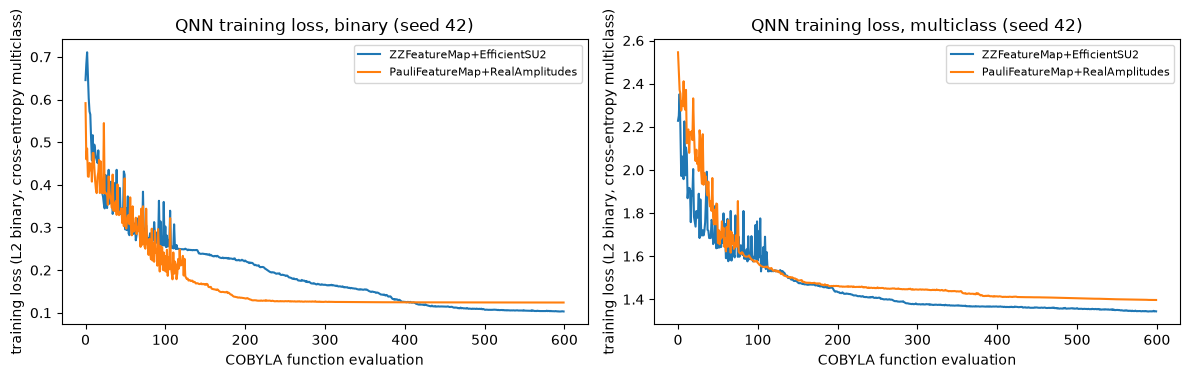

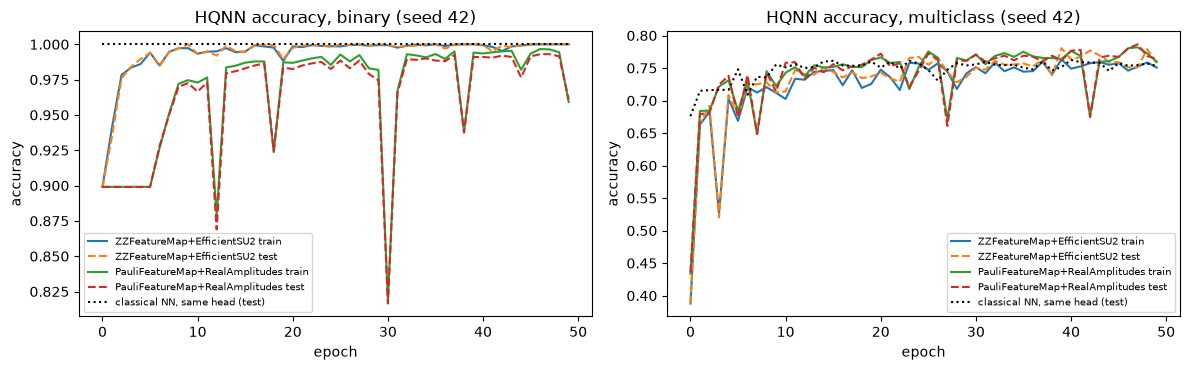

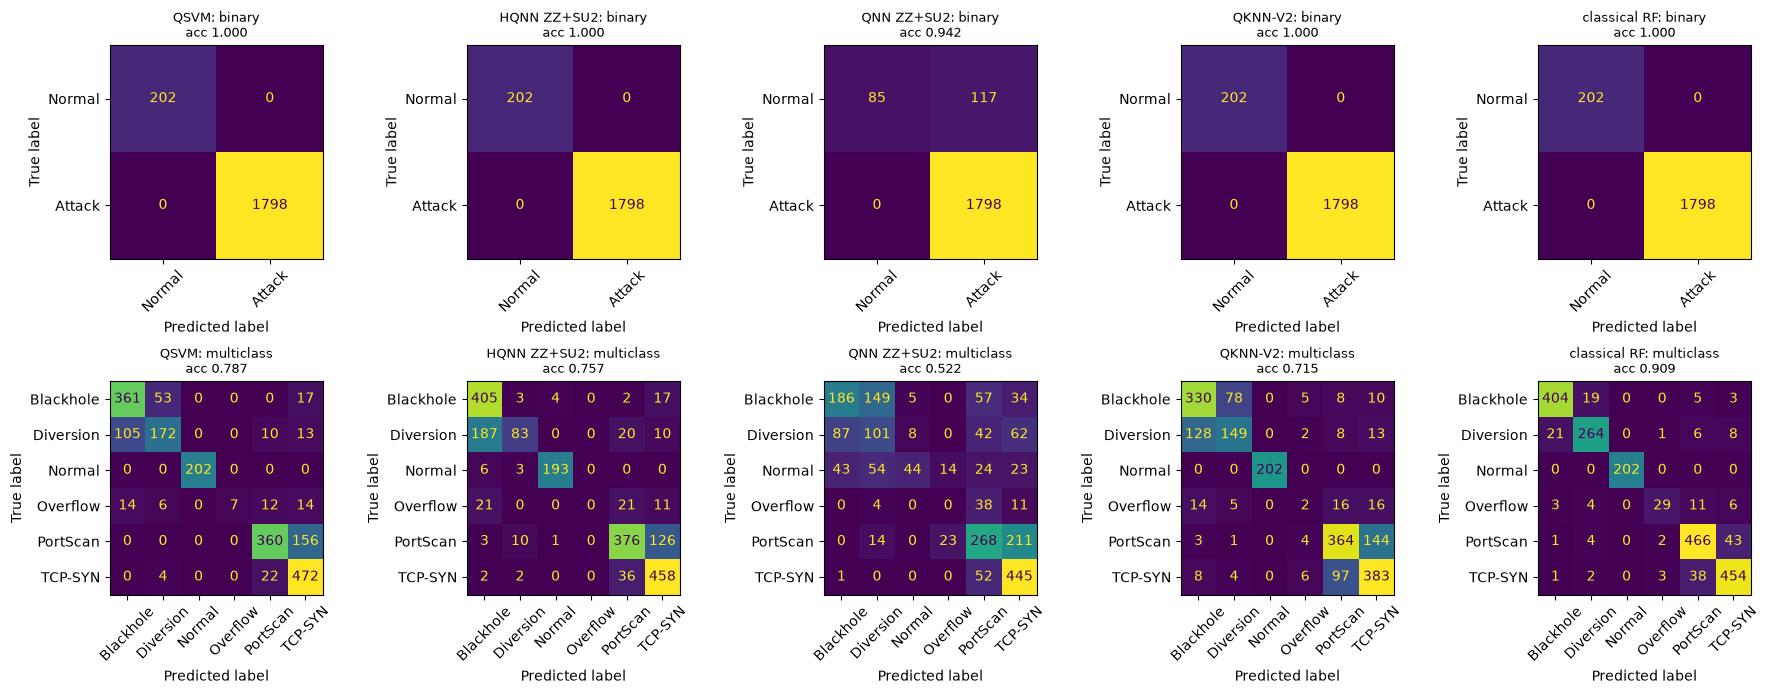

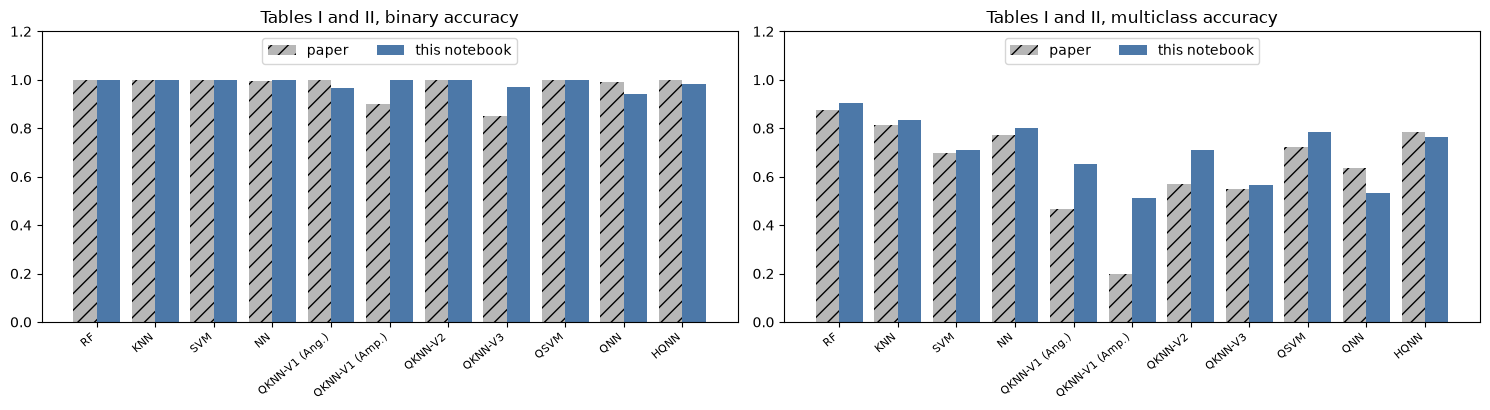

In [24]:
s0 = SEEDS[0]
# ---- the paper's Figure 10: QNN training loss, binary and multiclass, both combinations ----
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, task in zip(axes, TASKS):
    for fk, ak in COMBOS:
        ax.plot(QNN_LOSS[((fk, ak), task, s0)], label=COMBO_NAME[(fk, ak)])
    ax.set_xlabel("COBYLA function evaluation"); ax.set_ylabel("training loss (L2 binary, cross-entropy multiclass)"); ax.set_title(f"QNN training loss, {task} (seed {s0})"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

# ---- the paper's Figure 11: HQNN train / test accuracy per epoch ----
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, task in zip(axes, TASKS):
    for fk, ak in COMBOS:
        c = np.array(HQNN_CURVES[((fk, ak), task, s0)]); ax.plot(c[:, 1], label=f"{COMBO_NAME[(fk, ak)]} train"); ax.plot(c[:, 2], "--", label=f"{COMBO_NAME[(fk, ak)]} test")
    c = np.array(HQNN_CURVES[(("ctrl",), task, s0)]); ax.plot(c[:, 2], ":", color="k", label="classical NN, same head (test)")
    ax.set_xlabel("epoch"); ax.set_ylabel("accuracy"); ax.set_title(f"HQNN accuracy, {task} (seed {s0})"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

# ---- confusion matrices of the main models (first seed) ----
names_bin = ["Normal", "Attack"]
show = [("QSVM", "QSVM"), ("HQNN ZZFeatureMap+EfficientSU2", "HQNN ZZ+SU2"), ("QNN ZZFeatureMap+EfficientSU2", "QNN ZZ+SU2"), ("QKNN-V2", "QKNN-V2"), ("classical RF", "classical RF")]
fig, axes = plt.subplots(2, len(show), figsize=(3.6 * len(show), 7))
for j, (mk, label) in enumerate(show):
    for i, task in enumerate(TASKS):
        p = PREP[s0]; y, _ = targets(p, task); lab = names_bin if task == "binary" else CLASSES
        cm_ = confusion_matrix(y[p["ite"]], PRED[(mk, task, s0)], labels=list(range(len(lab))))
        ConfusionMatrixDisplay(cm_, display_labels=lab).plot(ax=axes[i, j], colorbar=False, xticks_rotation=45, values_format="d")
        axes[i, j].set_title(f"{label}: {task}\nacc {accuracy_score(y[p['ite']], PRED[(mk, task, s0)]):.3f}", fontsize=9)
plt.tight_layout(); plt.show()

# ---- the paper's Tables I and II redrawn: paper vs this notebook ----
PAPER_ACC = {  # (model label, task): accuracy of the paper (Tables I and II)
    ("RF", "binary"): 1.0, ("RF", "multiclass"): 0.8735, ("KNN", "binary"): 1.0, ("KNN", "multiclass"): 0.8145, ("SVM", "binary"): 1.0, ("SVM", "multiclass"): 0.6965,
    ("NN", "binary"): 0.995, ("NN", "multiclass"): 0.7710,
    ("QKNN-V1 (Ang.)", "binary"): 1.0, ("QKNN-V1 (Ang.)", "multiclass"): 0.4680, ("QKNN-V1 (Amp.)", "binary"): 0.9005, ("QKNN-V1 (Amp.)", "multiclass"): 0.1980,
    ("QKNN-V2", "binary"): 1.0, ("QKNN-V2", "multiclass"): 0.5690, ("QKNN-V3", "binary"): 0.85, ("QKNN-V3", "multiclass"): 0.55,
    ("QSVM", "binary"): 1.0, ("QSVM", "multiclass"): 0.7240, ("QNN", "binary"): 0.989, ("QNN", "multiclass"): 0.6355, ("HQNN", "binary"): 1.0, ("HQNN", "multiclass"): 0.7824}
MODEL_OF = {"RF": ["classical RF"], "KNN": ["classical KNN"], "SVM": ["classical SVM"], "NN": ["classical NN"],
            "QKNN-V1 (Ang.)": ["QKNN-V1 (angle)"], "QKNN-V1 (Amp.)": ["QKNN-V1 (amplitude)"], "QKNN-V2": ["QKNN-V2"], "QKNN-V3": ["QKNN-V3"], "QSVM": ["QSVM"],
            "QNN": ["QNN ZZFeatureMap+EfficientSU2", "QNN PauliFeatureMap+RealAmplitudes"], "HQNN": ["HQNN ZZFeatureMap+EfficientSU2", "HQNN PauliFeatureMap+RealAmplitudes"]}
def nb_acc(label, task):
    """Notebook accuracy of a paper row: the mean over seeds; for QNN / HQNN (two combinations in the paper) the better of the two."""
    return max(RESD[(RESD["model"] == m_) & (RESD["task"] == task)]["acc"].mean() for m_ in MODEL_OF[label])
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
labels = list(MODEL_OF)
for ax, task in zip(axes, TASKS):
    xs = np.arange(len(labels))
    ax.bar(xs - 0.2, [PAPER_ACC[(l_, task)] for l_ in labels], 0.4, label="paper", color="#999999", hatch="//", alpha=0.7)
    ax.bar(xs + 0.2, [nb_acc(l_, task) for l_ in labels], 0.4, label="this notebook", color="#4C78A8")
    ax.set_xticks(xs); ax.set_xticklabels(labels, rotation=40, ha="right", fontsize=8); ax.set_ylim(0, 1.2); ax.set_title(f"Tables I and II, {task} accuracy"); ax.legend(loc="upper center", ncol=2)
plt.tight_layout(); plt.show()

## 11. Side by side with the paper

Verdict rule (project convention): **reproduced** if the notebook value is within 0.02 of the paper's value (accuracy, mean F1); otherwise **not reached** (notebook lower) or **exceeded** (notebook higher), with the gap in accuracy points.
Where the paper reports one number for two architectures (QNN, HQNN), the better of the two is compared. Qualitative claims (orderings) are checked on the notebook's own means. **cannot be checked** marks claims for which the paper gives no numbers.

In [25]:
TOL = 0.02          # project convention: within 2 accuracy points / 0.02 F1 counts as reproduced
def verdict(nb, paper):
    d = nb - paper
    return "reproduced" if abs(d) <= TOL else (f"exceeded (+{d * 100:.1f} pts)" if d > 0 else f"not reached ({d * 100:.1f} pts)")

rows = []
for (lab, task), pv in PAPER_ACC.items():
    nv = nb_acc(lab, task)
    note = ""
    if lab == "QKNN-V3": note = f"{N_V3_TEST} test flows per seed x {len(SEEDS_V3)} seeds (paper: 40 flows, one run)"
    if lab in ("QNN", "HQNN"): note = "better of the two feature-map/ansatz combinations"
    rows.append({"claim": f"{lab}, {task}: accuracy", "paper": pv, "notebook": round(nv, 4), "verdict": verdict(nv, pv), "note": note})
# Table I mean F1 (macro F1 here)
PAPER_F1 = {("RF", "binary"): 1.0, ("RF", "multiclass"): 0.8771, ("KNN", "binary"): 1.0, ("KNN", "multiclass"): 0.8935, ("SVM", "binary"): 1.0, ("SVM", "multiclass"): 0.6773,
            ("NN", "binary"): 0.9864, ("NN", "multiclass"): 0.7325}
for (lab, task), pv in PAPER_F1.items():
    nv = RESD[(RESD["model"] == MODEL_OF[lab][0]) & (RESD["task"] == task)]["f1_macro"].mean()
    rows.append({"claim": f"{lab}, {task}: mean F1 (macro)", "paper": pv, "notebook": round(nv, 4), "verdict": verdict(nv, pv), "note": "paper does not define its 'mean F1'; macro-F1 used"})

# qualitative claims
acc = lambda m_, t: RESD[(RESD["model"] == m_) & (RESD["task"] == t)]["acc"].mean()
best_h = max(nb_acc("HQNN", "multiclass"), 0); nn_m = acc("classical NN", "multiclass")
rows.append({"claim": "multiclass: HQNN beats the classical NN (78.24 vs 77.10)", "paper": "yes", "notebook": f"HQNN {best_h:.4f} vs NN {nn_m:.4f}", "verdict": "reproduced" if best_h > nn_m else "not reached", "note": "classical NN = sklearn MLP (64, 32); the same-head control gives " + f"{acc('classical NN (same head, no quantum layer)', 'multiclass'):.4f}"})
rows.append({"claim": "multiclass: QSVM beats the classical SVM (72.40 vs 69.65)", "paper": "yes", "notebook": f"QSVM {acc('QSVM', 'multiclass'):.4f} vs SVM {acc('classical SVM', 'multiclass'):.4f}", "verdict": "reproduced" if acc("QSVM", "multiclass") > acc("classical SVM", "multiclass") else "not reached", "note": ""})
qml_multi = {"HQNN": nb_acc("HQNN", "multiclass"), "QSVM": acc("QSVM", "multiclass"), "QNN": nb_acc("QNN", "multiclass"), "QKNN-V2": acc("QKNN-V2", "multiclass"),
             "QKNN-V1 (Ang.)": acc("QKNN-V1 (angle)", "multiclass"), "QKNN-V1 (Amp.)": acc("QKNN-V1 (amplitude)", "multiclass")}
rk = sorted(qml_multi, key=qml_multi.get, reverse=True)
rows.append({"claim": "multiclass ranking of the QML models: HQNN > QSVM > QNN > QKNN-V2 > QKNN-V1 (Ang.) > QKNN-V1 (Amp.)", "paper": "HQNN > QSVM > QNN > QKNN-V2 > V1 Ang. > V1 Amp.",
             "notebook": " > ".join(rk), "verdict": "reproduced" if rk == ["HQNN", "QSVM", "QNN", "QKNN-V2", "QKNN-V1 (Ang.)", "QKNN-V1 (Amp.)"] else "not reached (different order)", "note": ""})
cls_m = {m_: acc(f"classical {m_}", "multiclass") for m_ in ["RF", "KNN", "SVM", "NN"]}
rk_c = sorted(cls_m, key=cls_m.get, reverse=True)
rows.append({"claim": "multiclass ranking of the classical models in Table I: RF > KNN > NN > SVM", "paper": "RF > KNN > NN > SVM", "notebook": " > ".join(rk_c), "verdict": "reproduced" if rk_c == ["RF", "KNN", "NN", "SVM"] else "not reached (different order)", "note": ""})
best_qml_m = max(qml_multi.values()); best_cls_m = max(cls_m.values())
rows.append({"claim": "(implied by the paper's own tables) no QML model beats the best classical model in the multiclass case", "paper": f"RF 0.8735 vs best QML 0.7824", "notebook": f"RF {best_cls_m:.4f} vs best QML {best_qml_m:.4f}", "verdict": "reproduced" if best_qml_m < best_cls_m else "not reached (a QML model is better here)", "note": "the paper's conclusion compares only with SVM and NN"})
# loss ordering of Fig. 10
fl = lambda combo, t: RESD[(RESD["model"] == f"QNN {COMBO_NAME[combo]}") & (RESD["task"] == t)]["final_loss"].mean()
l_b = (fl(("zz", "su2"), "binary"), fl(("pauli", "ra"), "binary")); l_m = (fl(("zz", "su2"), "multiclass"), fl(("pauli", "ra"), "multiclass"))
rows.append({"claim": "Fig. 10, binary: ZZ+EfficientSU2 has more difficulty reducing the loss than Pauli+RealAmplitudes", "paper": "yes", "notebook": f"final loss {l_b[0]:.3f} vs {l_b[1]:.3f}", "verdict": "reproduced" if l_b[0] > l_b[1] else "not reached", "note": "the two feature maps are the same circuit here, so only the ansatz differs"})
rows.append({"claim": "Fig. 10, multiclass: the opposite (ZZ+EfficientSU2 reduces the loss better)", "paper": "yes", "notebook": f"final loss {l_m[0]:.3f} vs {l_m[1]:.3f}", "verdict": "reproduced" if l_m[0] < l_m[1] else "not reached", "note": ""})
# feature selection
rows.append({"claim": "Section IV: the 4 features Port alive Duration, Packets Matched, Packets Looked Up, Active Flow Entries are the best combination", "paper": "best", "notebook": f"validation acc {PAPER_COMBO_ACC:.4f} vs best searched {COMBO_DF['validation accuracy'].iloc[0]:.4f}",
             "verdict": "reproduced" if PAPER_COMBO_ACC >= COMBO_DF["validation accuracy"].iloc[0] - TOL else f"not reached ({(PAPER_COMBO_ACC - COMBO_DF['validation accuracy'].iloc[0]) * 100:.1f} pts)", "note": f"search over the top {TOP_FOR_COMBOS} features of our RF importance ranking; RF only"})
rows.append({"claim": "Figs. 8 and 9 (accuracy of all feature combinations; accuracy vs number of samples)", "paper": "graphics only", "notebook": "-", "verdict": "cannot be checked", "note": "no numbers are given in the text"})
rows.append({"claim": "QKNN-V3 circuit details (Grover iterations, shots, k) and QSVM 'modified' feature map (X and RZ gates)", "paper": "not specified", "notebook": "reconstructed", "verdict": "cannot be checked", "note": "see the choices table"})
CMP = pd.DataFrame(rows)
print(CMP.to_string(index=False))
print("\nVerdict counts:"); print(CMP["verdict"].str.replace(r" \(.*\)", "", regex=True).value_counts().to_string())

n_te = len(PREP[SEEDS[0]]['ite'])
print(f"\nFor scale: the binomial standard error of an accuracy of 0.75 on {n_te} test flows is {100 * math.sqrt(0.75 * 0.25 / n_te):.2f} points, and of an accuracy of 0.75 on the 40 QKNN-V3 test flows {100 * math.sqrt(0.75 * 0.25 / 40):.1f} points.")

                                                                                                                           claim                                           paper                                                      notebook                       verdict                                                                       note
                                                                                                            RF, binary: accuracy                                             1.0                                                           1.0                    reproduced                                                                           
                                                                                                        RF, multiclass: accuracy                                          0.8735                                                         0.906           exceeded (+3.2 pts)                                            

## 12. Reading the paper critically

(Numbers below are those of the full run stored in this notebook: 10,000 flows, three seeds, mean +- std; QKNN-V3 five seeds of 200 flows; HQNN three seeds of 50 epochs.)

* **The binary task carries no information.** With the four chosen features every classical model reaches 100 % (paper, Table I; here too), and 90 % of the flows are attacks, so a constant "attack" classifier already scores 90 %: the paper's 90.05 % for QKNN-V1 (amplitude) is exactly that.
  All the ranking in the paper therefore rests on the multiclass column.
* **The headline compares against the weakest classical models.** In the multiclass case the paper's own Table I has a random forest at 87.35 % and a KNN at 81.45 %, both above every quantum model of Table II (best: HQNN 78.24 %). The conclusion ("QML can improve the results of classical ML") only compares HQNN with the NN (77.10 %) and QSVM with the SVM (69.65 %). Here the random forest reaches 90.6 +- 0.7 % and the best quantum model (QSVM) 78.3 +- 0.4 %.
* **The margins are within what one run can resolve.** The paper's gaps are 1.1 points (HQNN against NN) and 2.8 points (QSVM against SVM) from one run on 2,000 test flows, whose binomial standard error is about 1 point; no seeds, no confidence intervals. In this notebook the classical NN (64, 32) reaches 79.9 +- 1.1 % against 76.1 to 76.3 % for the HQNN, so *the HQNN advantage is not reproduced*, and a control with the same classical head but no quantum layer gives 75.9 +- 0.6 %, i.e. the quantum layer adds nothing measurable.
  The QSVM advantage *is* reproduced and larger (78.3 +- 0.4 % against 70.8 +- 0.3 % for an untuned RBF-SVM). That says the fixed quantum kernel suits these heavy-tailed [0, pi] features better than scikit-learn's default RBF kernel; it does not say a quantum kernel is needed: the classical SVM was not tuned (exercise 5), a KNN or a forest does better, and the 4-qubit kernel is cheap to simulate classically.
* **Several of the paper's numbers are not recovered, in both directions.** QKNN-V1 and V2 are 14 to 32 points *above* the paper in the multiclass case (paper 46.8 / 19.8 / 56.9 %, here 65.1 / 51.3 / 70.9 %), the QNN 10 points *below* (63.6 % against 53.2 %). The 19.8 % of the amplitude-encoded QKNN is below the share of the largest class (about 25 %) and almost at the 1/6 of a random guess, which points to an unusual normalisation or a bug in the original; here the same circuit gives 83 % with exact probabilities (first-seed ablation) and 51 % with 2048-shot noise.
  The swap test returns a probability with a resolution of about 0.01 after 2048 shots, which is not enough to order neighbours whose distances differ by less than that: **shot noise alone costs 13 to 32 points** in the multiclass case (first-seed ablation: QKNN-V2 83.7 % with exact probabilities against about 71 % with 2048 shots; amplitude encoding 83.4 % against about 51 %).
* **QKNN-V3 cannot work as described.** After the swap test the "similar" branch has probability `(1 + F)/2 >= 1/2`, so Grover iterations would overshoot; without them the index distribution has a contrast of at most 2:1 over 160 indices and the measured top-5 overlaps with the true 5 nearest neighbours by only 0.1 (chance 0.03).
  Its accuracy (97 / 56.5 +- 8.5 %) is thus a matter of shot noise, and the 85 % / 55 % of the paper on 40 test flows (standard error of about 7 points) says nothing either way. With an idealised comparator oracle the circuit is exactly a classical KNN (72.0 +- 8.3 %, classical Euclidean KNN 73.5 +- 4.9 %): no advantage is visible at this scale.
* **Selection on the test split and possible leakage.** The feature combination and the sample size are chosen by accuracy on the same 80/20 split on which the final models are evaluated. Here the paper's four features come out as the best of 210 combinations on a validation split (0.8895 against 0.8880), so the selection effect is small. A second concern is untested: UNR-IDD rows are consecutive counter snapshots of the same switch ports (`Port alive Duration`, cumulative counters), and a random split puts neighbouring snapshots of the same port in train and test, which can inflate every model, classical and quantum.
* **Simulation only.** Everything runs on exact 4-qubit simulators, in microseconds per circuit; the paper rightly notes that times are not comparable. An advantage in accuracy on four features and a few thousand flows is not an advantage in efficiency or scalability, which is what the introduction promises from "superposition and entanglement".
* **Missing details limit reproduction.** Figs. 1 to 7 are graphics only (pooling circuit, "modified" ZZFeatureMap), and `k`, `C`, hidden widths, batch size, learning rate, feature scaling, number of Grover iterations and shots are not given; every such choice is marked in the code and in the table above. The paper's `PauliFeatureMap` is, with the library defaults, the same circuit as the `ZZFeatureMap`; its Fig. 10 claim that the two combinations behave oppositely is reproduced for the multiclass loss but not for the binary one here (ZZ+EfficientSU2 reached the lower final loss in all three seeds in both tasks).

## 13. Exercises

1. **Scaling.** The paper does not say how the four features are scaled. Replace the [0, pi] min-max scaling (`prepare`) by standardisation followed by a clip to [-pi, pi], or by a `log1p` of the two packet counters, and re-run the QSVM and the classical SVM. Which model profits more? Why do the heavy-tailed counters matter for angle encoding?
2. **Shots versus exact.** The ablation table of section 5 shows that QKNN-V1 (amplitude) and QKNN-V2 lose accuracy through 2048-shot noise. Find the number of shots (`SHOTS_KNN`: 128, 512, 2048, 8192, `None`) at which they stop improving, and explain it from the size of the binomial noise relative to the gap between the distances of the 5th and 6th neighbour.
3. **Bandwidth.** Add more angle scales to `SCALES` and plot the QSVM validation accuracy against the scale for the multiclass task. Is the paper's circuit (scale 1) a good or a lucky choice? Does a quantum kernel with a small scale behave like a classical kernel?
4. **Feature maps.** Give the `PauliFeatureMap` different Paulis, e.g. `["Y", "ZZ"]`, so that it is no longer the same circuit as the ZZFeatureMap, and train the QNN again. Does the ordering of the two combinations in the paper's Fig. 10 change?
5. **A fair classical control.** The paper compares the HQNN with a classical NN of unspecified size. Give the same-head control a number of parameters equal to that of the HQNN's head plus its circuit, tune its learning rate on the validation split, and re-run the comparison. Does the claim "HQNN beats the NN" survive? Next, repeat the comparison for the random forest of Table I, which is the strongest model in the multiclass case.